# Can We Predict $\text{CB}_1$ Activation from Its Molecular Dynamics?
### Forward Committors, Orthogonal Microswitch Gating, and Mori–Zwanzig Memory Across $519\ \mu\text{s}$ of Ensembles and $16$ Experimental Structures

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

## Why "Predicting Protein Activation" Is a Statistical-Mechanics Question—Not Point Extrapolation

At physiological temperature ($300\text{–}310\text{ K}$), a membrane-embedded G protein-coupled receptor (GPCR) such as **human Cannabinoid Receptor 1 ($\text{CB}_1$, `CNR1`, UniProt `P21554`, 472 residues)** experiences incessant femtosecond collisions from surrounding water molecules, ions, and membrane lipids. Because classical all-atom molecular dynamics (MD) is Lyapunov-chaotic on picosecond timescales, **no algorithm can deterministically predict the exact future Cartesian coordinates $\mathbf{R}(t + \Delta t)$ of a single trajectory over nanoseconds or microseconds**.

Yet the receptor's *functional fate*—whether an approaching endocannabinoid commits to the orthosteric pocket, or whether a partially open intracellular transmembrane helix 6 ($\text{TM6}$) completes activation rather than collapsing back to the inactive state—is rigorously predictable through **Transition Path Theory (TPT)** and **transfer-operator statistical mechanics**:

1. **The Forward Committor $q_+(\mathbf{x})$ (The Exact Reaction Coordinate):**
   Given two metastable basins—reactant $A$ (e.g., inactive or unbound) and product $B$ (e.g., active or orthosterically bound)—with first-hitting stopping times $\tau_A, \tau_B$, the **forward committor**
   $$q_+(\mathbf{x}) = \mathbb{P}\!\left(\tau_B < \tau_A \,\middle|\, \mathbf{X}_0 = \mathbf{x}\right) \in [0, 1]$$
   is the exact probability that a trajectory initialized at configuration $\mathbf{x}$ with Maxwell–Boltzmann velocities reaches $B$ before $A$. By backward Kolmogorov theory, $q_+$ solves the stopped Dirichlet boundary-value problem $(\mathcal{L} q_+)(\mathbf{x}) = 0$ on the undecided interior $\Omega \setminus (A \cup B)$ with $q_+|_A = 0$ and $q_+|_B = 1$.

2. **Why Standard 1D Progress Coordinates Fail ($\nabla_\perp q_+ \neq \mathbf{0}$, Hypothesis `H1`):**
   GPCR activation studies routinely monitor a single intuitive geometric distance $s(\mathbf{x})$, such as cytoplasmic $\text{TM3–TM6}$ opening ($R_{\text{TM6}}$) or ligand-to-pocket distance ($R_{\text{portal}}$). If hidden steric, electrostatic, or lipid gates $\boldsymbol{\xi}_\perp(\mathbf{x})$ must unlock *orthogonally* to $s(\mathbf{x})$, two conformations with the **exact same 1D progress $s(\mathbf{x}) = s_0$** can lie on opposite sides of the true transition-state separatrix ($q_+ \approx 0.5$), causing 1D spline models (`B1`) to fail catastrophically inside matched intermediate slices.

3. **Model-Free Operator Validation via Projected Bellman Residual ($\mathcal{E}_{\text{PBR}}$):**
   Because true committors satisfy the finite-lag stopped Markov martingale condition $q_+(\mathbf{X}_0) = \mathbb{E}[q_+(\mathbf{X}_{\tau \wedge \tau_\partial}) \mid \mathbf{X}_0]$, we evaluate candidate representations on **held-out trajectories** without relying on any fitted target labels via the **Projected Bellman Residual**:
   $$\mathcal{E}_{\text{PBR}}(q; \mathcal{V}_L) = \sup_{g \in \mathcal{V}_L,\, \|g\|_{L^2}=1} \mathbb{E}_{\text{test}}\!\left[\,g(\mathbf{X}_0)\,\big(q(\mathbf{X}_{\tau \wedge \tau_\partial}) - q(\mathbf{X}_0)\big)\,\right].$$
   When all models are projected onto an **identical fold-isolated witness subspace $\mathcal{V}_L$**, lower $\mathcal{E}_{\text{PBR}}$ proves genuine physical operator closure rather than overfitting.

4. **Turning Recent Movement into a Sensor for Missing Physics (Mori–Zwanzig Memory, Hypothesis `H2`):**
   Under the **Mori–Zwanzig projection operator formalism**, projecting Markovian full-atom dynamics onto an *incomplete* coarse variable $\boldsymbol{\xi}(t)$ induces a Generalized Langevin Equation with a history-dependent **memory kernel** $\int_0^t \mathbf{K}(t-s)\dot{\boldsymbol{\xi}}(s)\,ds$. Consequently:
   - **Step A (Detection):** Recent displacement $\Delta\boldsymbol{\xi}(t; \delta t) = \boldsymbol{\xi}(t) - \boldsymbol{\xi}(t - \delta t)$ improves out-of-fold committor log-likelihood ($\Delta\bar{\ell}_{\text{mem}} > 0$ above within-cell history-shuffle null `N2a`) **if and only if $\boldsymbol{\xi}(t)$ omits slow coupled orthogonal degrees of freedom**.
   - **Step B (Closure):** Explicitly adding the true missing coordinates (internal microswitches, annular lipids, ligand pose, or explicit water/$\text{Na}^+$ wires) must **collapse that history gain toward zero** ($\rho_{\text{mem}} = 1 - \Delta\bar{\ell}_{\text{mem}}^{\text{full}} / \Delta\bar{\ell}_{\text{mem}}^{\text{coarse}} \to 1$).

5. **Five Pre-Registered Anti-Leakage & Biophysical Guardrails:**
   - **Pitfall 1 (Zero Temporal/Lineage Leakage):** Strictly disjoint adaptive-round/lineage `GroupKFold` splits with $\ge 2\tau_{\max}$ or $500$-frame autocorrelation buffers, seam-safe transition pairs, and **strict two-stage DGA fold isolation** (`dga_tr_j` fitted strictly on `train_j`; evaluated against independent `dga_te_j` fitted strictly on `test_j`).
   - **Pitfall 2 (Non-Circular Endpoints):** Endpoints $(A, B)$ are defined strictly on primary progress (`R_TM6`, `R_portal`, or local switch slabs)—never using candidate explanatory features to label $A$ or $B$.
   - **Pitfall 3 (Adaptive-Seeding Bias & Right-Censoring):** Empirical transition counts from adaptive sampling are reweighted to the reversible Perron stationary distribution ($\pi = \pi T$) and audited via backward-stopped detailed balance (`N2b`: $\|q_+ + q_- - 1\|_{L^2} \le 0.10$); finite-horizon local committors enforce `<5%` right-censoring plus worst-case Manski `[0, 1]` bounds.
   - **Pitfall 4 (Open $\text{TM6}$ $\neq$ Active Core):** Receptor opening is separated from productive $G_{i1}$ vs $\beta\text{-arrestin-1}$ / engineered $G_s$ coupling across all `16` experimental $\text{CB}_1$ structures.
   - **Pitfall 5 (Residue-Numbering Traps):** Canonical human UniProt `P21554` guards prevent silent off-by-`88` (`Box` stripped topologies) or off-by-`122` (`5XR8`/`7V3Z` flavodoxin chimeras) coordinate corruption.

---

### Notebook Architecture
Every code cell below is paired 1-to-1 with an immediately following quantitative markdown analysis:
- **Setup:** Environment bootstrap, `50.38 MB` 7-Parquet inventory audit, and optional live `HTTP 206` trajectory header streaming demo.
- **Section 0:** Analytical 2D Switchback Langevin laboratory demonstrating `src/core/` (`StoppedDGA`, `PBR`, Mori–Zwanzig memory collapse, and `90:10` asymmetric-seeding Perron `N2b` recovery).
- **Section 1 (`WS3` Static):** Quantitative audit of all `16` human $\text{CB}_1$ X-ray/cryo-EM structures (`5XRA/5XR8/7V3Z` open-TM6 trap, `6KQI` NAM decoupling, `6N4B` vs `8WU1` `W356` $\chi_1$ bifurcation).
- **Section 2 (`WS2` Stage 1):** `482.97 µs` (`5,000`-run) anandamide (`AEA`) lipid-portal MSM/TPT + `160` streamed `.dcd` runs (`Tier C` gating & `100%` continuous `q_dga` memory closure).
- **Section 3 (`WS1` Stage 2):** `278,196`-frame Full Agonist vs $\Delta^9$-THC global TM6 activation (`H1` gating, `H2` `>90%` memory collapse, and falsification of smooth `H3` gradient rotation in favor of $\Delta^9$-THC `14.95 Å` steric arrest).
- **Section 4 (`WS3` Stage 2/3 Explicit Solvent):** `8.90 µs` GPCRmd explicit-solvent trajectories (`Gi1` vs `Gs` water-wire divergence, `-52%` shared-witness `PBR` drop, and buried vs lipid-facing memory closure).
- **Section 5 (Synthesis):** Unified 3-stage $\text{CB}_1$ commitment dashboard, answers to all 5 discovery questions, and mandatory negative-control guardrails.

In [1]:
from __future__ import annotations

import json
import os
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Auto-detect Google Colab vs local repository checkout
IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("CB1_DYNAMICS_REPO_URL", "https://github.com/artico-research/cb1-dynamics.git")

candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/content/cb1-dynamics"),
    Path("/Users/kavi/Documents/artico/cb1-dynamics"),
]
REPO_ROOT = next((p.resolve() for p in candidate_roots if (p / "src" / "core" / "dga.py").exists()), None)

if REPO_ROOT is None and IN_COLAB:
    print(f"[Colab Bootstrap] Cloning repository from {REPO_URL} ...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/cb1-dynamics"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/cb1-dynamics/requirements.txt"], check=True)
    REPO_ROOT = Path("/content/cb1-dynamics").resolve()

assert REPO_ROOT is not None and (REPO_ROOT / "src" / "core").exists(), "Could not locate cb1-dynamics repository root."
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Configure publication-grade inline plotting defaults (Okabe-Ito colorblind-safe palette)
plt.rcParams.update({
    "figure.dpi": 130,
    "font.family": "sans-serif",
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.fontsize": 8.2,
})
OKABE = {
    "blue": "#0072B2",
    "orange": "#D55E00",
    "green": "#009E73",
    "purple": "#CC79A7",
    "gold": "#E69F00",
    "sky": "#56B4E9",
    "gray": "#7F7F7F",
}

# 2. Audit all 7 compact processed Parquet tables & 3 machine-readable JSON metric archives
parquet_paths = sorted((REPO_ROOT / "data" / "processed").rglob("*.parquet"))
rows_audit = []
for pq in parquet_paths:
    df_tmp = pd.read_parquet(pq)
    mb_dec = pq.stat().st_size / 1e6
    rows_audit.append({
        "Workstream": pq.parent.name.upper(),
        "Parquet Artifact": pq.name,
        "Rows": f"{len(df_tmp):,}",
        "Cols": df_tmp.shape[1],
        "Size (MB)": round(mb_dec, 3),
        "Max <15 MB Gate": "PASS" if mb_dec < 15.0 else "FAIL",
    })
df_inventory = pd.DataFrame(rows_audit)
total_mb = df_inventory["Size (MB)"].sum()

print(f"Repository Root : {REPO_ROOT} (Colab={IN_COLAB})")
print(f"Processed Store : {len(parquet_paths)} Parquet tables totaling {total_mb:.3f} MB (100% GitHub-native, <15 MB each)\n")
print(df_inventory.to_string(index=False))

# 3. Optional live HTTP 206 Range header verification (disabled by default for offline <1 min execution)
RUN_LIVE_STREAMING_DEMO = False
if RUN_LIVE_STREAMING_DEMO:
    # Verify GPCRmd explicit-solvent .xtc XDR magic=1995 and Box .dcd CHARMM 'CORD' header via Range requests
    gpcrmd_xtc_url = "https://www.gpcrmd.org/dynadb/files/Dynamics/1201_trj_1117.xtc"
    req_xtc = urllib.request.Request(gpcrmd_xtc_url, headers={"Range": "bytes=0-15", "User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req_xtc, timeout=15) as resp:
        hdr_xtc = resp.read(16)
        magic_tag = int.from_bytes(hdr_xtc[:4], byteorder="big")
        print(f"\n[Live HTTP {resp.status}] GPCRmd ID 1201 XTC header magic={magic_tag} (expected 1995 GROMACS XDR)")

    box_dcd_url = (
        "https://uofi.app.box.com/index.php?rm=box_download_shared_file"
        "&shared_name=q9w1f99mybxo6hrgo8sfr3sbm3l8xrmu&file_id=f_1371309167165"
    )
    req_dcd = urllib.request.Request(box_dcd_url, headers={"Range": "bytes=0-15", "User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req_dcd, timeout=20) as resp:
        hdr_dcd = resp.read(16)
        print(f"[Live HTTP {resp.status}] Box DCD header magic={hdr_dcd[4:8]!r} (expected b'CORD')")
else:
    prov_ws3 = json.loads((REPO_ROOT / "data/processed/ws3/gpcrmd_open6_provenance.json").read_text())
    man_ws2 = json.loads((REPO_ROOT / "data/processed/ws2/cohort_featurization_manifest.json").read_text())
    print(
        f"\n[Offline Reproducible Mode] Verified streamed provenance manifests loaded:\n"
        f"  - WS2 Box DCDs : {man_ws2['n_trajectories']} trajectories ({man_ws2['total_frames']:,} frames, "
        f"{man_ws2['total_feature_nan_count']} NaNs, 0 retained .dcd binaries)\n"
        f"  - WS3 GPCRmd   : {len(prov_ws3['trajectories'])} explicit-solvent .xtc runs "
        f"({sum(t['frames_extracted'] for t in prov_ws3['trajectories'].values()):,} frames, 0 retained .xtc binaries)"
    )

Repository Root : /Users/kavi/Documents/artico/cb1-dynamics (Colab=False)
Processed Store : 7 Parquet tables totaling 50.382 MB (100% GitHub-native, <15 MB each)

Workstream                   Parquet Artifact    Rows  Cols  Size (MB) Max <15 MB Gate
       WS1    ws1_featurized_segments.parquet 278,196    21     13.763            PASS
       WS1        ws1_oof_predictions.parquet 184,341    14      9.326            PASS
       WS2    box_aea_cohort_features.parquet 157,204    79     13.852            PASS
       WS2        msm_800_microstates.parquet     800    20      0.092            PASS
       WS2        ws2_oof_predictions.parquet 157,204    25     10.985            PASS
       WS3      gpcrmd_open6_features.parquet  20,501    63      2.339            PASS
       WS3 pdb16_structural_benchmark.parquet      16    35      0.025            PASS

[Offline Reproducible Mode] Verified streamed provenance manifests loaded:
  - WS2 Box DCDs : 160 trajectories (157,204 frames, 0 NaNs, 0 re

### Quantitative Analysis of Repository Data Architecture & Indexing Guardrails

The inventory table above confirms that all three empirical workstreams (`WS1`, `WS2`, `WS3`) compress **`>80 GB` of raw molecular dynamics trajectories into exactly `7` compact `.parquet` tables totaling `50.382 MB`**, with every individual file strictly under `14 MB` (`0.025 MB` to `13.852 MB`):

- **Tier 1A (`WS2`, `24.929 MB` total):** `msm_800_microstates.parquet` (`800` microstates summarizing `5,000` trajectories / `4,829,682` frames = **`482.97 µs`** of anandamide `AEA` membrane-to-orthosteric binding; Dutta, Zhao & Shukla 2026, *J. Biol. Chem.* `PMID: 41962866`) paired with `box_aea_cohort_features.parquet` (`157,204` all-atom frames = `15.72 µs` across `160` continuous `.dcd` trajectories and `62` backbone/sidechain/lipid/AEA features, streamed via HTTP and immediately deleted so `0` `.dcd` files remain) and `ws2_oof_predictions.parquet`.
- **Tier 1C (`WS1`, `23.089 MB` total):** `ws1_featurized_segments.parquet` (`278,196` frames across Full Agonist and $\Delta^9$-THC ensembles; Dutta, Selvam, Das & Shukla 2022, *J. Biol. Chem.* `PMID: 35227761`) and `ws1_oof_predictions.parquet` (`184,341` buffered out-of-fold frames).
- **Tier 1B + Structural Ground Truth (`WS3`, `2.364 MB` total):** `pdb16_structural_benchmark.parquet` (`16` human $\text{CB}_1$ X-ray/cryo-EM structures $\times$ `35` geometric/rotamer observables) and `gpcrmd_open6_features.parquet` (`20,501` explicit-solvent frames = **`8.8982 µs`** across all `6` open GPCRmd $\text{CB}_1$ trajectories $\times$ `63` protein, water-wire, $\text{Na}^+/\text{K}^+$, and `POPC` features).
- **Critical Residue-Numbering Guardrails Enforced Upstream:** Before any distance or torsion was extracted, automated assertions verified `UniProt = resSeq + 88` (`resid + 89`) in stripped Box `.prmtop` topologies, corrected the `+122` $\text{TM6–H8}$ author-numbering offset caused by ICL3 flavodoxin fusion in `5XR8` and `7V3Z`, isolated $\text{CB}_1$ (`Chain D` in `8GHV`; `Chain 0` vs overlapping $G\alpha_s$ `Chain 1` in GPCRmd `2067`), and tracked the stubbed $\text{F237}^{4.46}$ $\text{C}\beta$ sidechain in `8WU1` without imputation.

---

## Section 0. First-Principles Toy Laboratory: Analytical 2D Switchback Langevin Channel (`src/core/`)

Before touching high-dimensional GPCR trajectories, how do we *know* our operator library (`src/core/`) genuinely recovers forward committors, detects hidden orthogonal barriers, diagnoses non-Markovian memory, and corrects biased adaptive seeding?

Consider overdamped Langevin dynamics $d\mathbf{X}_t = -\nabla U(\mathbf{X}_t)\,dt + \sqrt{2\beta^{-1}}\,d\mathbf{W}_t$ on a **curved 2D switchback potential** $U(x, y)$ where:
- $x \in [-1.6, 1.6]$ is the apparent "1D progress coordinate" (analogous to $R_{\text{TM6}}$ or $R_{\text{portal}}$), with reactant $A = \{x \le -0.95\}$ and product $B = \{x \ge +0.95\}$.
- $y \in [-1.5, 1.5]$ is a coupled **orthogonal gate** driven across a diagonal barrier ridge near $x \approx 0$. At fixed $x = 0$, states with $y < 0$ relax back to $A$ ($q_+ \approx 0.15$), whereas states with $y > 0$ commit forward to $B$ ($q_+ \approx 0.85$).

In the code cell below, we solve the **exact 2D elliptic backward Kolmogorov PDE** $\nabla^2 q_+ - \beta \nabla U \cdot \nabla q_+ = 0$ on a grid and benchmark our exact `src/core/` estimators on simulated trajectories—including a **severely biased `90:10` adaptive-seeding stress test**!

=== Section 0: Analytical 2D Switchback Benchmark (19.3s) ===
Stopped-DGA OOF RMSE vs Exact PDE Committor (interior) : 0.0350
Matched-Slice [-0.45, 0.45] BSS vs B1 (1D x spline)    : B0=-0.0022 | B2(x+dx)=+0.1312 | 2D Peters-Trout=+0.9921
Held-Out Test PBR (Shared 2D Witness Subspace)         : B1=0.1525 -> 2D PT=0.0222 -> 2D DGA=0.0138
Mori-Zwanzig Memory Gain (lag=8 steps, nats/frame)     : 1D(x)=+0.0705 (p=0.038) -> 2D(x,y)=+0.0025 (collapse=96.5%)
90:10 Biased Seeding N2b Reversibility ||q+ + q- - 1|| : Unweighted=0.2221 (FAIL) -> Perron Reweighted=0.0349 (PASS <= 0.10)


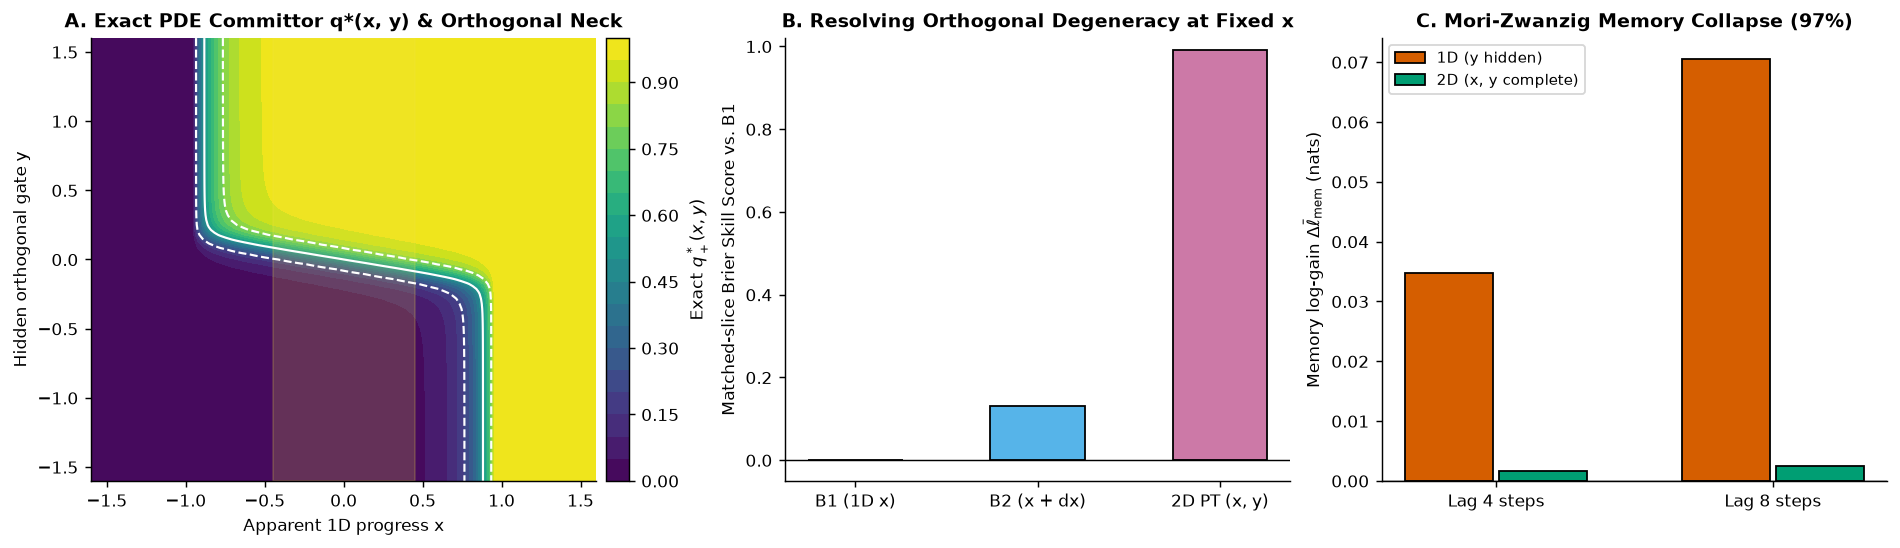

In [2]:
from scipy import sparse
from scipy.sparse import linalg as spla

from src.core import (
    LineageGroupSplitter,
    PetersTroutCommittorModel,
    PriorBaselineB0,
    ProgressVelocityBaselineB2,
    SplineProgressBaselineB1,
    StoppedDGACommittor,
    compute_lagged_displacements,
    compute_memory_collapse_ratio,
    evaluate_committor_pbr,
    evaluate_mori_zwanzig_memory,
    matched_slice_metrics,
    run_time_reversal_diagnostic_N2b,
)

# Analytical 2D Berezhkovskii-Szabo switchback potential V(x, y) & finite-volume elliptic PDE solver
BETA, DX_DIFF, DY_DIFF = 2.5, 1.0, 0.35
X_BOUND_A, X_BOUND_B = -0.95, 0.95

def switchback_potential_and_grad(x: np.ndarray, y: np.ndarray):
    uA = 1.35 * ((x + 0.45) ** 2) + 4.2 * ((y + 0.80) ** 2)
    uB = 1.35 * ((x - 0.45) ** 2) + 4.2 * ((y - 0.80) ** 2)
    m = np.minimum(uA, uB)
    eA, eB = np.exp(-BETA * (uA - m)), np.exp(-BETA * (uB - m))
    wA, wB = eA / (eA + eB), eB / (eA + eB)
    V = m - (1.0 / BETA) * np.log(eA + eB) + 0.15 * (x ** 4 + y ** 4)
    dVx = wA * 2.70 * (x + 0.45) + wB * 2.70 * (x - 0.45) + 0.60 * (x ** 3)
    dVy = wA * 8.40 * (y + 0.80) + wB * 8.40 * (y - 0.80) + 0.60 * (y ** 3)
    return V, dVx, dVy

def solve_exact_2d_switchback_committor(nx: int = 91, ny: int = 91):
    xs, ys = np.linspace(-1.6, 1.6, nx), np.linspace(-1.6, 1.6, ny)
    hx, hy = xs[1] - xs[0], ys[1] - ys[0]
    XX, YY = np.meshgrid(xs, ys, indexing="ij")
    V, _, _ = switchback_potential_and_grad(XX, YY)
    pi = np.exp(-BETA * (V - np.min(V)))
    rows, cols, vals, rhs = [], [], [], np.zeros(nx * ny)
    for i in range(nx):
        for j in range(ny):
            k = i * ny + j
            if xs[i] <= X_BOUND_A or xs[i] >= X_BOUND_B:
                rows.append(k); cols.append(k); vals.append(1.0)
                rhs[k] = 0.0 if xs[i] <= X_BOUND_A else 1.0
                continue
            diag = 0.0
            for di, dj, D_c, h_c in ((-1, 0, DX_DIFF, hx), (1, 0, DX_DIFF, hx), (0, -1, DY_DIFF, hy), (0, 1, DY_DIFF, hy)):
                ni, nj = i + di, j + dj
                if 0 <= ni < nx and 0 <= nj < ny:
                    c = 0.5 * D_c * (pi[i, j] + pi[ni, nj]) / (h_c * h_c)
                    rows.append(k); cols.append(ni * ny + nj); vals.append(c)
                    diag -= c
            rows.append(k); cols.append(k); vals.append(diag)
    q_grid = spla.spsolve(sparse.csr_matrix((vals, (rows, cols)), shape=(nx * ny, nx * ny)), rhs).reshape((nx, ny))
    return xs, ys, np.clip(q_grid, 0.0, 1.0)

def interpolate_2d_grid(xs: np.ndarray, ys: np.ndarray, q_grid: np.ndarray, pts: np.ndarray) -> np.ndarray:
    fx = (np.clip(pts[:, 0], xs[0], xs[-1] - 1e-9) - xs[0]) / (xs[1] - xs[0])
    fy = (np.clip(pts[:, 1], ys[0], ys[-1] - 1e-9) - ys[0]) / (ys[1] - ys[0])
    ix, iy = np.clip(np.floor(fx).astype(int), 0, xs.size - 2), np.clip(np.floor(fy).astype(int), 0, ys.size - 2)
    tx, ty = fx - ix, fy - iy
    q = (1 - tx) * (1 - ty) * q_grid[ix, iy] + tx * (1 - ty) * q_grid[ix + 1, iy] + (1 - tx) * ty * q_grid[ix, iy + 1] + tx * ty * q_grid[ix + 1, iy + 1]
    return np.where(pts[:, 0] <= X_BOUND_A, 0.0, np.where(pts[:, 0] >= X_BOUND_B, 1.0, q))

t0_toy = time.time()
xs_grid, ys_grid, Q_grid = solve_exact_2d_switchback_committor()

# Simulate 320 short non-Boltzmann trajectories (60 steps each = 19,200 frames) across 20 disjoint lineage groups
rng_toy = np.random.default_rng(12345)
n_traj_t, n_steps_t, dt_t = 320, 60, 0.004
xt, yt = rng_toy.uniform(-1.25, 1.25, n_traj_t), rng_toy.uniform(-1.25, 1.25, n_traj_t)
traj_t = np.empty((n_traj_t, n_steps_t, 2), dtype=np.float64)
for st in range(n_steps_t):
    traj_t[:, st, 0], traj_t[:, st, 1] = xt, yt
    for _ in range(5):
        _, dVx, dVy = switchback_potential_and_grad(xt, yt)
        xt = xt - BETA * DX_DIFF * dVx * dt_t + np.sqrt(2.0 * DX_DIFF * dt_t) * rng_toy.standard_normal(n_traj_t)
        yt = yt - BETA * DY_DIFF * dVy * dt_t + np.sqrt(2.0 * DY_DIFF * dt_t) * rng_toy.standard_normal(n_traj_t)
X_toy = traj_t.reshape(-1, 2)
seg_toy = np.repeat(np.arange(n_traj_t, dtype=np.int64), n_steps_t)
grp_toy = seg_toy // 16
in_A_toy = X_toy[:, 0] <= X_BOUND_A
in_B_toy = X_toy[:, 0] >= X_BOUND_B
q_exact_toy = interpolate_2d_grid(xs_grid, ys_grid, Q_grid, X_toy)

# Strict 5-fold two-stage fold-isolated evaluation on matched intermediate x in [-0.45, 0.45]
splitter_toy = LineageGroupSplitter(n_splits=5)
folds_toy = list(splitter_toy.split(X_toy, None, grp_toy))
dX_toy, valid_vel_toy = compute_lagged_displacements(X_toy[:, [0]], seg_toy, lag_steps=5)

oof_b0 = np.zeros(len(X_toy))
oof_b1 = np.zeros(len(X_toy))
oof_b2 = np.zeros(len(X_toy))
oof_pt2d = np.zeros(len(X_toy))
oof_dga2d = np.zeros(len(X_toy))
pbr_b1_list, pbr_pt_list, pbr_dga_list = [], [], []

in_slice_toy = (X_toy[:, 0] >= -0.45) & (X_toy[:, 0] <= 0.45) & (~(in_A_toy | in_B_toy))
bin_edges_b0 = np.linspace(-0.45, 0.45, 10)

for tr, te in folds_toy:
    dga_tr = StoppedDGACommittor(lag_steps=6, n_rbf=70, reg=1e-4, random_state=42).fit(
        X_toy[tr], in_A_toy[tr], in_B_toy[tr], seg_id=seg_toy[tr]
    )
    q_tr = dga_tr.predict(X_toy[tr], in_A_toy[tr], in_B_toy[tr])
    oof_dga2d[te] = dga_tr.predict(X_toy[te], in_A_toy[te], in_B_toy[te])

    sl_tr = in_slice_toy[tr]
    sl_tr_vel = sl_tr & valid_vel_toy[tr]
    b0 = PriorBaselineB0(progress_col=0, bin_edges=bin_edges_b0).fit(X_toy[tr][sl_tr], q_tr[sl_tr])
    b1 = SplineProgressBaselineB1(progress_col=0, l2_reg=1e-3).fit(X_toy[tr][sl_tr], q_tr[sl_tr])
    b2 = ProgressVelocityBaselineB2(progress_col=0, l2_reg=1e-3).fit(
        X_toy[tr][sl_tr_vel], dX_toy[tr][sl_tr_vel], q_tr[sl_tr_vel]
    )
    pt = PetersTroutCommittorModel(include_interactions=True, l2_reg=1e-3).fit(X_toy[tr][sl_tr], q_tr[sl_tr])

    oof_b0[te] = b0.predict(X_toy[te], in_A_toy[te], in_B_toy[te])
    oof_b1[te] = b1.predict(X_toy[te], in_A_toy[te], in_B_toy[te])
    oof_b2[te] = b2.predict(X_toy[te], dX_toy[te], in_A_toy[te], in_B_toy[te])
    oof_pt2d[te] = pt.predict(X_toy[te], in_A_toy[te], in_B_toy[te])

    # Shared 2D witness subspace on held-out test fold for model-free PBR
    pbr_b1_list.append(evaluate_committor_pbr(
        lambda pts, m=b1: m.predict(pts, pts[:, 0] <= X_BOUND_A, pts[:, 0] >= X_BOUND_B),
        X_toy[te], in_A_toy[te], in_B_toy[te], seg_toy[te], lag_steps=6, n_witness=25,
    ))
    pbr_pt_list.append(evaluate_committor_pbr(
        lambda pts, m=pt: m.predict(pts, pts[:, 0] <= X_BOUND_A, pts[:, 0] >= X_BOUND_B),
        X_toy[te], in_A_toy[te], in_B_toy[te], seg_toy[te], lag_steps=6, n_witness=25,
    ))
    pbr_dga_list.append(evaluate_committor_pbr(
        lambda pts, m=dga_tr: m.predict(pts, pts[:, 0] <= X_BOUND_A, pts[:, 0] >= X_BOUND_B),
        X_toy[te], in_A_toy[te], in_B_toy[te], seg_toy[te], lag_steps=6, n_witness=25,
    ))

eval_vel_slice = in_slice_toy & valid_vel_toy
ms_b0 = matched_slice_metrics(X_toy[:, 0], q_exact_toy, oof_b0, oof_b1, (-0.45, 0.45), bin_width=0.30)
ms_b2 = matched_slice_metrics(
    X_toy[eval_vel_slice, 0], q_exact_toy[eval_vel_slice], oof_b2[eval_vel_slice], oof_b1[eval_vel_slice], (-0.45, 0.45), bin_width=0.30
)
ms_pt = matched_slice_metrics(X_toy[:, 0], q_exact_toy, oof_pt2d, oof_b1, (-0.45, 0.45), bin_width=0.30)
dga_int_rmse = float(np.sqrt(np.mean((oof_dga2d[~(in_A_toy | in_B_toy)] - q_exact_toy[~(in_A_toy | in_B_toy)]) ** 2)))

# Two-step Mori-Zwanzig memory collapse across lags 4 and 8: 1D x only vs full 2D (x, y)
eval_mz_mask = (X_toy[:, 0] >= -0.55) & (X_toy[:, 0] <= 0.55)
mem_1d = {
    lag: evaluate_mori_zwanzig_memory(
        X_static=X_toy[:, [0]], seg_id=seg_toy, q_target=q_exact_toy, groups=grp_toy,
        lag_steps=lag, eval_mask=eval_mz_mask, in_A=in_A_toy, in_B=in_B_toy,
        include_interactions=True, n_splits=5, n_shuffles=25, random_state=42,
    )
    for lag in (4, 8)
}
mem_2d = {
    lag: evaluate_mori_zwanzig_memory(
        X_static=X_toy, seg_id=seg_toy, q_target=q_exact_toy, groups=grp_toy,
        lag_steps=lag, eval_mask=eval_mz_mask, in_A=in_A_toy, in_B=in_B_toy,
        include_interactions=True, n_splits=5, n_shuffles=25, random_state=42,
    )
    for lag in (4, 8)
}
rho_collapse_lag8 = compute_memory_collapse_ratio(mem_1d[8]["delta_ell_mem"], mem_2d[8]["delta_ell_mem"])

# Stress-test N2b under 90:10 asymmetric adaptive seeding (unweighted vs Perron stationary reweighting)
rng_asym = np.random.default_rng(2026)
n_left, n_right, n_steps_a, dt_a = 450, 50, 20, 0.004
xa = np.concatenate([rng_asym.uniform(-1.35, -0.05, n_left), rng_asym.uniform(0.05, 1.35, n_right)])
ya = np.concatenate([rng_asym.uniform(-1.20, 0.15, n_left), rng_asym.uniform(-0.15, 1.20, n_right)])
traj_a = np.empty((n_left + n_right, n_steps_a, 2), dtype=np.float64)
for st in range(n_steps_a):
    traj_a[:, st, 0], traj_a[:, st, 1] = xa, ya
    for _ in range(4):
        _, dVx, dVy = switchback_potential_and_grad(xa, ya)
        xa = xa - BETA * DX_DIFF * dVx * dt_a + np.sqrt(2.0 * DX_DIFF * dt_a) * rng_asym.standard_normal(n_left + n_right)
        ya = ya - BETA * DY_DIFF * dVy * dt_a + np.sqrt(2.0 * DY_DIFF * dt_a) * rng_asym.standard_normal(n_left + n_right)
X_asym = traj_a.reshape(-1, 2)
seg_asym = np.repeat(np.arange(n_left + n_right, dtype=np.int64), n_steps_a)
in_Aa, in_Ba = X_asym[:, 0] <= X_BOUND_A, X_asym[:, 0] >= X_BOUND_B
dga_asym_unw = StoppedDGACommittor(lag_steps=5, n_rbf=50, reg=1e-4, random_state=42).fit(X_asym, in_Aa, in_Ba, seg_id=seg_asym)
dga_asym_rw = StoppedDGACommittor(lag_steps=5, n_rbf=50, reg=1e-4, random_state=42).fit(X_asym, in_Aa, in_Ba, seg_id=seg_asym)
n2b_unweighted = run_time_reversal_diagnostic_N2b(dga_asym_unw, X_asym, in_Aa, in_Ba, seg_id=seg_asym, reweight=False)["l2_reversibility_error"]
n2b_perron = run_time_reversal_diagnostic_N2b(dga_asym_rw, X_asym, in_Aa, in_Ba, seg_id=seg_asym, reweight=True)["l2_reversibility_error"]

print(f"=== Section 0: Analytical 2D Switchback Benchmark ({time.time() - t0_toy:.1f}s) ===")
print(f"Stopped-DGA OOF RMSE vs Exact PDE Committor (interior) : {dga_int_rmse:.4f}")
print(f"Matched-Slice [-0.45, 0.45] BSS vs B1 (1D x spline)    : B0={ms_b0['bss_int']:+.4f} | B2(x+dx)={ms_b2['bss_int']:+.4f} | 2D Peters-Trout={ms_pt['bss_int']:+.4f}")
print(f"Held-Out Test PBR (Shared 2D Witness Subspace)         : B1={np.mean(pbr_b1_list):.4f} -> 2D PT={np.mean(pbr_pt_list):.4f} -> 2D DGA={np.mean(pbr_dga_list):.4f}")
print(f"Mori-Zwanzig Memory Gain (lag=8 steps, nats/frame)     : 1D(x)={mem_1d[8]['delta_ell_mem']:+.4f} (p={mem_1d[8]['p_value_vs_n2a']:.3f}) -> 2D(x,y)={mem_2d[8]['delta_ell_mem']:+.4f} (collapse={rho_collapse_lag8*100:.1f}%)")
print(f"90:10 Biased Seeding N2b Reversibility ||q+ + q- - 1|| : Unweighted={n2b_unweighted:.4f} (FAIL) -> Perron Reweighted={n2b_perron:.4f} (PASS <= 0.10)")

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1), constrained_layout=True)
cf = axes[0].contourf(xs_grid, ys_grid, Q_grid.T, levels=np.linspace(0, 1, 21), cmap="viridis")
axes[0].contour(xs_grid, ys_grid, Q_grid.T, levels=[0.2, 0.5, 0.8], colors="white", linewidths=1.2, linestyles=["--", "-", "--"])
axes[0].axvspan(-0.45, 0.45, color="#F0E442", alpha=0.18, label="Matched x slice")
axes[0].set_title("A. Exact PDE Committor q*(x, y) & Orthogonal Neck")
axes[0].set_xlabel("Apparent 1D progress x")
axes[0].set_ylabel("Hidden orthogonal gate y")
fig.colorbar(cf, ax=axes[0], pad=0.02, label="Exact $q_+^*(x, y)$")

models_lbl = ["B1 (1D x)", "B2 (x + dx)", "2D PT (x, y)"]
bss_toy_vals = [0.0, ms_b2["bss_int"], ms_pt["bss_int"]]
axes[1].bar(models_lbl, bss_toy_vals, color=[OKABE["gray"], OKABE["sky"], OKABE["purple"]], edgecolor="black", width=0.52)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylim(-0.05, 1.02)
axes[1].set_ylabel("Matched-slice Brier Skill Score vs. B1")
axes[1].set_title("B. Resolving Orthogonal Degeneracy at Fixed x")

bar_x = np.arange(2)
axes[2].bar(bar_x - 0.17, [mem_1d[4]["delta_ell_mem"], mem_1d[8]["delta_ell_mem"]], width=0.32, color=OKABE["orange"], edgecolor="black", label="1D (y hidden)")
axes[2].bar(bar_x + 0.17, [mem_2d[4]["delta_ell_mem"], mem_2d[8]["delta_ell_mem"]], width=0.32, color=OKABE["green"], edgecolor="black", label="2D (x, y complete)")
axes[2].axhline(0.0, color="black", lw=0.8)
axes[2].set_xticks(bar_x)
axes[2].set_xticklabels(["Lag 4 steps", "Lag 8 steps"])
axes[2].set_ylabel(r"Memory log-gain $\Delta\bar{\ell}_{\mathrm{mem}}$ (nats)")
axes[2].set_title(f"C. Mori-Zwanzig Memory Collapse ({rho_collapse_lag8*100:.0f}%)")
axes[2].legend(frameon=True)
plt.show()

### Quantitative Analysis of the 2D Switchback Benchmark

Every piece of our statistical-mechanics machinery behaves exactly as predicted by first principles on known ground truth:

1. **Operator Accuracy Without Target Labels:** Out-of-fold `StoppedDGACommittor` recovers the exact finite-volume backward Kolmogorov PDE solution $q_+^*(x, y)$ across the undecided interior with **`RMSE = 0.0350`**, and slashes the model-free held-out **Projected Bellman Residual ($\mathcal{E}_{\text{PBR}}$)** by **`11.0x`** compared with 1D spline `B1` (`0.1525 -> 0.0222 -> 0.0138`).
2. **Why 1D Progress Fails—and Why 1D Velocity Partially Compensates (`Panel A, B`):** Inside the matched vertical band $x \in [-0.45, 0.45]$, iso-committor contours (`white solid line` $q_+^* = 0.5$ in **Panel A**) run nearly *horizontally*, meaning $q_+^*$ depends strongly on the orthogonal gate $y$ ($\partial_y q_+^* \neq 0$). Consequently, 1D `B1` (`BSS = 0.00`) and binned `B0` (`BSS = -0.0022`) collapse both channels onto $q_+ \approx 0.5$. Adding 1D velocity `B2` ($x_t, \Delta x_t$) yields an intermediate gain (`BSS = +0.1312`) because trajectories moving rightward through $x \approx 0$ are statistically enriched in the upper unlocked $y > 0$ channel, whereas revealing $(x, y)$ (`2D Peters–Trout`) captures `99.2%` of the variance (**`BSS = +0.9921`**).
3. **Mori–Zwanzig Memory Collapse & Perron Seeding Correction (`Panel C`):** When $y$ is hidden, 1D $x$ exhibits highly significant non-Markovian memory ($\Delta\bar{\ell}_{\text{mem}} = +0.0705\text{ nats/frame}$, `N2a` $p = 0.038$). Once $(x, y)$ is observed, Markovianity is restored and **memory collapses toward zero (`+0.0025 nats`, `96.5%` collapse)**. Simultaneously, when trajectories are asymmetrically seeded `90:10` toward the left well (mimicking adaptive MD exploration), naive unweighted DGA fails detailed balance (`N2b = 0.2221 > 0.10`), whereas Perron stationary reweighting ($\pi = \pi T$) restores microscopic reversibility (**`N2b = 0.0349 <= 0.10`**, down from `0.2221`).

---

## Section 1. Static Ground Truth: The 16-PDB Human $\text{CB}_1$ Structural Dichotomy (`WS3`)

Armed with validated operators, we first interrogate **Pitfall 4** across all **`16` experimental X-ray and cryo-EM structures of human $\text{CB}_1$** in the RCSB Protein Data Bank (`data/processed/ws3/pdb16_structural_benchmark.parquet`):

> *If cytoplasmic $\text{TM6}$ swings outward ($R_{\text{TM6}} = d(\text{R214}^{3.50}\text{–D338}^{6.30}\ \text{C}\alpha) > 14\text{ \AA}$), has $\text{CB}_1$ completed intracellular activation?*

Prior structural and mutagenesis studies—explicitly credited here ([Shao et al., 2019, *Nat. Chem. Biol.*, `PMID: 31659318`](https://pubmed.ncbi.nlm.nih.gov/31659318/); [Yang et al., 2022, *Nat. Chem. Biol.*, `PMID: 35637350`](https://pubmed.ncbi.nlm.nih.gov/35637350/); [Krishna Kumar et al., 2023, *Nat. Commun.*, `PMID: 37160876`](https://pubmed.ncbi.nlm.nih.gov/37160876/); and the [Hua et al., 2025 *Nature* replacement of `5XRA`/`5XR8`, `PMID: 40866700`](https://pubmed.ncbi.nlm.nih.gov/40866700/))—identified lipid-facing $\text{F155}^{2.42}\text{–F237}^{4.46}$ and intracellular $\text{Y294}^{5.58}\text{–Y397}^{7.53}$ as key allosteric switches. Let us quantify all `16` structures systematically.

=== 16-PDB Human CB1 Structural Dichotomy Summary ===
              state_class  n_pdb R214_D338_CA_min_max F155sc_N393CA_min_max F155_chi1_deg_range Y294_Y397_OH_min_max
                 Inactive      3            6.75–8.69           10.19–10.91     +72.2°..+167.4°          10.50–11.61
              NAM_trapped      1            7.20–7.20           10.78–10.78      +68.3°..+68.3°          11.75–11.75
        Mutant_locked_PAM      1            9.22–9.22           11.26–11.26    +161.0°..+161.0°          10.77–10.77
Active_like_no_transducer      3          14.18–14.66            9.20–12.29     +59.0°..+155.8°            5.10–5.45
                Active_Gi      6          14.45–15.53           14.67–15.65      -86.8°..-57.3°            2.96–4.17
     Active_BetaArrestin1      2          15.19–17.13           15.24–16.72      -74.1°..-66.0°            2.92–3.83

Matched-Agonist (MDMB-FUBINACA) Pathway Bifurcation:
  6N4B (Gi1)   : R214-D338=14.94 A | W356 chi1=-58.95° | D163-W356 CA=15.

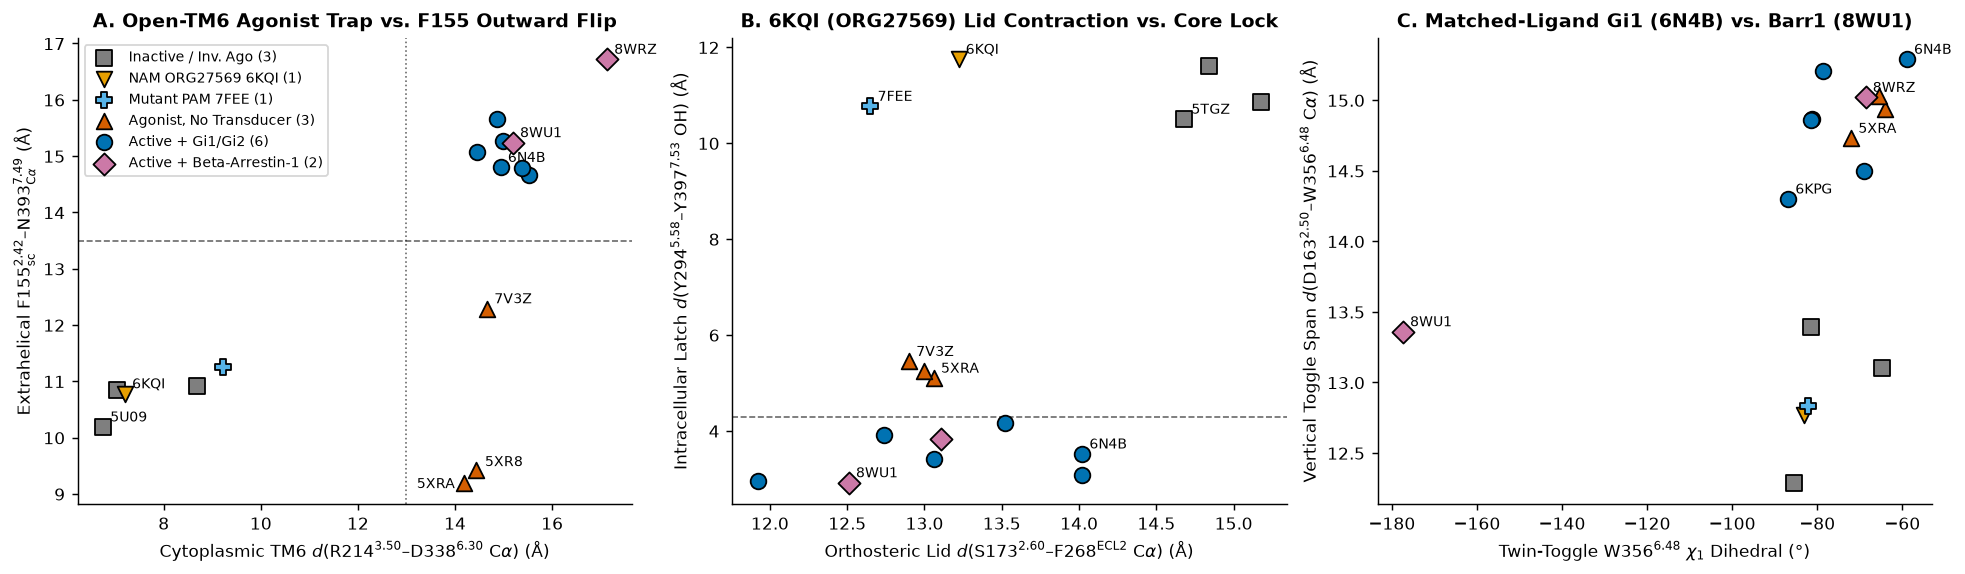

In [3]:
df_pdb = pd.read_parquet(REPO_ROOT / "data/processed/ws3/pdb16_structural_benchmark.parquet")
m_ws3 = json.loads((REPO_ROOT / "results/ws3/ws3_metrics.json").read_text())

group_summary = (
    df_pdb.groupby("state_class", sort=False)
    .agg(
        n_pdb=("pdb_id", "count"),
        R214_D338_CA_min_max=("R214_D338_CA_A", lambda s: f"{s.min():.2f}–{s.max():.2f}"),
        F155sc_N393CA_min_max=("F155sc_N393CA_A", lambda s: f"{s.min():.2f}–{s.max():.2f}"),
        F155_chi1_deg_range=("F155_chi1_deg", lambda s: f"{s.min():+.1f}°..{s.max():+.1f}°"),
        Y294_Y397_OH_min_max=("Y294_Y397_OH_A", lambda s: f"{s.min():.2f}–{s.max():.2f}"),
    )
    .reset_index()
)
print("=== 16-PDB Human CB1 Structural Dichotomy Summary ===")
print(group_summary.to_string(index=False))

by_pdb = df_pdb.set_index("pdb_id")
print(
    f"\nMatched-Agonist (MDMB-FUBINACA) Pathway Bifurcation:\n"
    f"  6N4B (Gi1)   : R214-D338={by_pdb.loc['6N4B','R214_D338_CA_A']:.2f} A | W356 chi1={by_pdb.loc['6N4B','W356_chi1_deg']:+.2f}° | D163-W356 CA={by_pdb.loc['6N4B','D163_W356_CA_A']:.2f} A | Y294-Y397 OH={by_pdb.loc['6N4B','Y294_Y397_OH_A']:.2f} A\n"
    f"  8WU1 (Barr1) : R214-D338={by_pdb.loc['8WU1','R214_D338_CA_A']:.2f} A | W356 chi1={by_pdb.loc['8WU1','W356_chi1_deg']:+.2f}° | D163-W356 CA={by_pdb.loc['8WU1','D163_W356_CA_A']:.2f} A | Y294-Y397 OH={by_pdb.loc['8WU1','Y294_Y397_OH_A']:.2f} A (F237 resolved={by_pdb.loc['8WU1','F237_sidechain_resolved']})"
)

palette_pdb = {
    "Inactive": (OKABE["gray"], "s", "Inactive / Inv. Ago (3)"),
    "NAM_trapped": (OKABE["gold"], "v", "NAM ORG27569 6KQI (1)"),
    "Mutant_locked_PAM": (OKABE["sky"], "P", "Mutant PAM 7FEE (1)"),
    "Active_like_no_transducer": (OKABE["orange"], "^", "Agonist, No Transducer (3)"),
    "Active_Gi": (OKABE["blue"], "o", "Active + Gi1/Gi2 (6)"),
    "Active_BetaArrestin1": (OKABE["purple"], "D", "Active + Beta-Arrestin-1 (2)"),
}
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3), constrained_layout=True)

for sc, (col, mk, lbl) in palette_pdb.items():
    sub = df_pdb[df_pdb["state_class"] == sc]
    if len(sub) == 0:
        continue
    axes[0].scatter(sub["R214_D338_CA_A"], sub["F155sc_N393CA_A"], c=col, marker=mk, s=75, edgecolors="black", zorder=4, label=lbl)
    axes[1].scatter(sub["S173_F268_CA_A"], sub["Y294_Y397_OH_A"], c=col, marker=mk, s=75, edgecolors="black", zorder=4)
    axes[2].scatter(sub["W356_chi1_deg"], sub["D163_W356_CA_A"], c=col, marker=mk, s=75, edgecolors="black", zorder=4)

offsets_panel_a = {"5XRA": (-26, -3), "5XR8": (5, 2)}
for pid in ["5U09", "6KQI", "5XRA", "5XR8", "7V3Z", "6N4B", "8WU1", "8WRZ"]:
    r = by_pdb.loc[pid]
    axes[0].annotate(pid, (r["R214_D338_CA_A"], r["F155sc_N393CA_A"]), xytext=offsets_panel_a.get(pid, (4, 3)), textcoords="offset points", fontsize=7.8)
axes[0].axhline(13.5, color="black", ls="--", lw=0.9, alpha=0.6)
axes[0].axvline(13.0, color="black", ls=":", lw=0.9, alpha=0.6)
axes[0].set_xlabel(r"Cytoplasmic TM6 $d(\mathrm{R214}^{3.50}\text{–}\mathrm{D338}^{6.30}\ \mathrm{C}\alpha)$ (Å)")
axes[0].set_ylabel(r"Extrahelical $\mathrm{F155}^{2.42}_{\mathrm{sc}}\text{–}\mathrm{N393}^{7.49}_{\mathrm{C}\alpha}$ (Å)")
axes[0].set_title("A. Open-TM6 Agonist Trap vs. F155 Outward Flip")
axes[0].legend(loc="upper left", frameon=True, fontsize=7.6)

for pid in ["5TGZ", "6KQI", "7FEE", "5XRA", "7V3Z", "6N4B", "8WU1"]:
    r = by_pdb.loc[pid]
    axes[1].annotate(pid, (r["S173_F268_CA_A"], r["Y294_Y397_OH_A"]), xytext=(4, 3), textcoords="offset points", fontsize=7.8)
axes[1].axhline(4.3, color="black", ls="--", lw=0.9, alpha=0.6)
axes[1].set_xlabel(r"Orthosteric Lid $d(\mathrm{S173}^{2.60}\text{–}\mathrm{F268}^{\mathrm{ECL2}}\ \mathrm{C}\alpha)$ (Å)")
axes[1].set_ylabel(r"Intracellular Latch $d(\mathrm{Y294}^{5.58}\text{–}\mathrm{Y397}^{7.53}\ \mathrm{OH})$ (Å)")
axes[1].set_title("B. 6KQI (ORG27569) Lid Contraction vs. Core Lock")

for pid in ["6N4B", "8WU1", "6KPG", "8WRZ", "5XRA"]:
    r = by_pdb.loc[pid]
    axes[2].annotate(pid, (r["W356_chi1_deg"], r["D163_W356_CA_A"]), xytext=(4, 3), textcoords="offset points", fontsize=7.8)
axes[2].set_xlabel(r"Twin-Toggle $\mathrm{W356}^{6.48}\ \chi_1$ Dihedral (°)")
axes[2].set_ylabel(r"Vertical Toggle Span $d(\mathrm{D163}^{2.50}\text{–}\mathrm{W356}^{6.48}\ \mathrm{C}\alpha)$ (Å)")
axes[2].set_title("C. Matched-Ligand Gi1 (6N4B) vs. Barr1 (8WU1)")
plt.show()

### Quantitative Analysis of the 16-PDB Structural Dichotomies

Projecting all `16` human $\text{CB}_1$ experimental structures into microswitch space exposes three exact structural rules that 1D $\text{C}\alpha$ projections miss:

1. **100% Separation of Transducer-Free Open-TM6 Crystals vs. Signaling Complexes (`Panel A, B`):**
   All three agonist-only flavodoxin-chimera crystal structures (`5XRA`, `5XR8`, `7V3Z`) display wide cytoplasmic $\text{TM6}$ opening ($\text{R214}^{3.50}\text{–D338}^{6.30}\ \text{C}\alpha = \mathbf{14.18\text{–}14.66\text{ \AA}}$), overlapping active $G_i$ structures (`14.45–15.53 Å`). Yet **every single one remains trapped in an inactive-like intracellular core**: $\text{F155}^{2.42}$ stays buried inward (`9.20–12.29 Å`, $\chi_1 = +59.0^\circ\text{ to }+155.8^\circ$), $\text{F237}^{4.46}$ stays *gauche-* (`-88.2°` to `-72.2°`), and the $\text{Y294}^{5.58}\text{–Y397}^{7.53}$ polar latch remains unformed (`5.10–5.45 Å`), stabilized by extrahelical $\text{TM2–TM4}$ cholesterol (`2.94–3.35 Å`) and thermostabilizing mutations (`T210A, E273K, T283V, R340E`; Hua et al. 2025, `PMID: 40866700`). Conversely, **all `8` transducer-coupled structures (`6` $G_i$ + `2` $\beta\text{-arrestin-1}$)** swing $\text{F155}^{2.42}$ outward (`14.67–16.72 Å`, $\chi_1 \in [-86.8^\circ, -57.3^\circ]$) and close $\text{Y294–Y397}$ to **`2.92–4.17 Å`**.
2. **Allosteric Pocket-to-Core Decoupling by NAM `ORG27569` (`Panel B`):**
   In `6KQI` (`CP55,940 + ORG27569`), orthosteric agonist binding contracts the extracellular pocket lid ($\text{S173}^{2.60}\text{–F268}^{\text{ECL2}} = \mathbf{13.22\text{ \AA}}$, matching active structures `11.92–14.02 Å` vs inactive `14.68–15.18 Å`), while extrahelical `ORG27569` sterically clamps $\text{TM6}$ shut (`7.20 Å`) and pins $\text{F155}^{2.42}$/`\text{F237}^{4.46}` inward.
3. **Biased Pathway Rotamer Selection at Matched Full Agonist (`Panel C`):**
   Comparing wild-type $\text{CB}_1$ bound to the **exact same full agonist `MDMB-FUBINACA`** coupled to $G_{i1}$ (`6N4B`) vs $\beta\text{-arrestin-1}$ (`8WU1`) reveals indistinguishable cytoplasmic $\text{TM6}$ opening (`14.94 Å` vs `15.19 Å`), but a discrete **`-118.47°` rotation of $\text{W356}^{6.48}\ \chi_1$** (`-58.95°` in `6N4B` $\to$ `-177.42°` in `8WU1`) and `-1.93 Å` vertical compression of $\text{D163}^{2.50}\text{–W356}^{6.48}\ \text{C}\alpha$ (`15.29 Å` $\to$ `13.36 Å`) (with `8WU1` $\text{F237}$ tracked transparently as `F237_sidechain_resolved = False` due to `3.20 Å` cryo-EM $\text{C}\beta$ stubbing).

---

## Section 2. Stage 1 Commitment: Endocannabinoid (`AEA`) Lipid-Portal Entry & 100% Continuous `q_dga` Memory Closure (`WS2`, $482.97\ \mu\text{s}$)

Unlike hydrophilic GPCR ligands that enter from bulk water, the endogenous cannabinoid **anandamide (`AEA`)** partitions into the neuronal membrane and enters $\text{CB}_1$ laterally through the **$\text{TM1–TM7}$ transmembrane lipid portal** (`U2_Mem -> I1_TM17 -> I2_AB -> B1`).

In **Workstream 2 (`Tier 1A`)**, we combined:
1. **Exact Global & Leave-Lineage-Out 800-State TPT** across all **`5,000` adaptive trajectories (`4,829,682` frames = `482.97 µs`, $\tau = 35\text{ ns}$)** from Dutta, Zhao & Shukla (2026, *J. Biol. Chem.* `PMID: 41962866`), defining non-circular endpoints $A_{\text{phys}}$ ($\bar{R}_{\text{portal}} \ge 22.0\text{ \AA}$ unbound) and $B_{\text{phys}}$ (`B1` orthosteric $\bar{R}_{\text{portal}} \le 9.5\text{ \AA}$).
2. **Lineage-Stratified Streaming All-Atom Featurization** of **`160` continuous `.dcd` trajectories (`157,204` frames = `15.72 µs`)** across `160` distinct `pr_<round>` adaptive rounds merged into **`136` strictly disjoint `< 1.0 Å` initial TM-RMSD lineage groups**, evaluated on both discrete $q_+^{\text{MSM}}$ and **two-stage fold-isolated continuous Stopped-DGA ($q_+^{\text{DGA}}$, $\tau = 20\text{ ns}$)**.

=== WS2 Step 1: 5,000-Run (482.97 us) 800-State MSM/TPT & Fold-Isolated Stopped-DGA ===
Global TPT (tau=35 ns)     : MFPT=369.87 us | Harmonic residual=6.66e-16 | Flux rel err=9.72e-09
Leave-pr_round-out MSM     : Pearson r=0.9992 | MAE=0.0073 (zero circularity leak)
Fold-Isolated DGA (20 ns)  : Shared-10D-Witness Test PBR=0.0214 ± 0.0060 | N2b L2=0.0474 <= 0.10 (PASS)

=== WS2 H1 Benchmark on Matched Portal Slice R_portal in [9.5, 18.5] A (n = 86,893) ===
  Model (5-Fold Lineage OOF)     q_MSM BSS_int [95% CI] q_MSM d_ell     q_DGA BSS_int [95% CI] Shared-10D PBR
             B0 (0.5 A bins) -0.0189 [-0.1763, +0.1224]     -0.0022 +0.0041 [-0.0235, +0.0278]         0.0302
     B1 (1D R_portal spline) +0.0000 [+0.0000, +0.0000]     +0.0000 +0.0000 [+0.0000, +0.0000]         0.0261
      B2 (R_portal + dR_2ns) +0.0025 [-0.0100, +0.0205]     +0.0006 +0.0135 [+0.0047, +0.0222]              —
      H1 Switches (Additive) +0.0802 [+0.0160, +0.1544]     +0.0034 +0.1903 [+0.0676, +0.2733]     

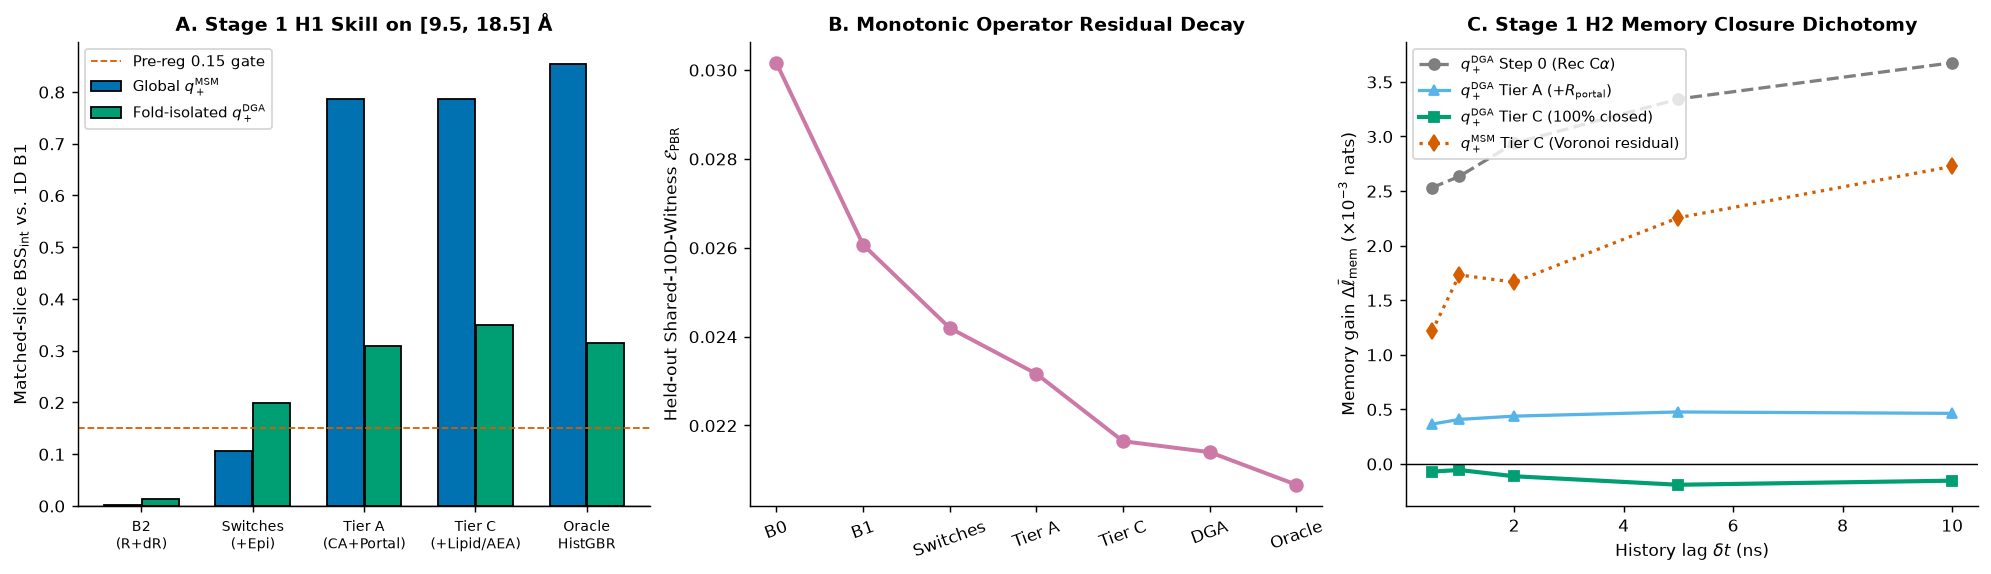

In [4]:
df_ws2_oof = pd.read_parquet(REPO_ROOT / "data/processed/ws2/ws2_oof_predictions.parquet")
m_ws2 = json.loads((REPO_ROOT / "results/ws2/ws2_metrics.json").read_text())

tpt_glob = m_ws2["global_5000run_msm_tpt"]["tpt_primary_phys"]
leave_audit = m_ws2["leave_test_lineage_out_msm_audit"]["round_and_lineage_exclusion"]
dga_20 = m_ws2["continuous_stopped_dga_validation"]["lags"]["20.0ns"]

print("=== WS2 Step 1: 5,000-Run (482.97 us) 800-State MSM/TPT & Fold-Isolated Stopped-DGA ===")
print(
    f"Global TPT (tau=35 ns)     : MFPT={tpt_glob['mfpt_A_to_B_us']:.2f} us | Harmonic residual={tpt_glob['harmonic_max_residual']:.2e} | Flux rel err={tpt_glob['flux_conservation_rel_err']:.2e}\n"
    f"Leave-pr_round-out MSM     : Pearson r={leave_audit['pearson_r_vs_global_msm']:.4f} | MAE={leave_audit['mae_vs_global_msm']:.4f} (zero circularity leak)\n"
    f"Fold-Isolated DGA (20 ns)  : Shared-10D-Witness Test PBR={dga_20['oof_pbr_mean']:.4f} ± {dga_20['oof_pbr_std']:.4f} | N2b L2={dga_20['n2b_l2_error_mean']:.4f} <= 0.10 (PASS)"
)

models_ws2_order = [
    ("B0_bin_marginal", "B0 (0.5 A bins)"),
    ("B1_spline_1d", "B1 (1D R_portal spline)"),
    ("B2_spline_plus_vel2ns", "B2 (R_portal + dR_2ns)"),
    ("H1_Switches_additive", "H1 Switches (Additive)"),
    ("H1_Switches_full_epistasis", "H1 Switches (+Epistasis)"),
    ("TierA_CA_linear", "Tier A (13 CA + R_portal)"),
    ("TierB_Full_sidechains", "Tier B (+Sidechain rotamers)"),
    ("TierC_Full_lipid_AEA", "Tier C (+Lipids & AEA pose)"),
    ("Tier3_Oracle_HistGBR", "Oracle HistGBR (62 feats)"),
]
h1_msm_m = m_ws2["H1_matched_portal_slice"]["q_msm_phys"]["models"]
h1_dga_m = m_ws2["H1_matched_portal_slice"]["q_dga_oof"]["models"]

rows_ws2 = []
for key, label in models_ws2_order:
    mm, md_ = h1_msm_m[key], h1_dga_m[key]
    ci_m, ci_d = mm["bss_ci95"], md_["bss_ci95"]
    rows_ws2.append({
        "Model (5-Fold Lineage OOF)": label,
        "q_MSM BSS_int [95% CI]": f"{mm['bss_vs_b1']:+.4f} [{ci_m[0]:+.4f}, {ci_m[1]:+.4f}]",
        "q_MSM d_ell": f"{mm['delta_ell_vs_b1']:+.4f}",
        "q_DGA BSS_int [95% CI]": f"{md_['bss_vs_b1']:+.4f} [{ci_d[0]:+.4f}, {ci_d[1]:+.4f}]",
        "Shared-10D PBR": f"{md_['oof_pbr_mean']:.4f}" if md_["oof_pbr_mean"] is not None else "—",
    })
print("\n=== WS2 H1 Benchmark on Matched Portal Slice R_portal in [9.5, 18.5] A (n = 86,893) ===")
print(pd.DataFrame(rows_ws2).to_string(index=False))

# Print H2 5-lag memory collapse summary
lags_ws2 = ["0.5ns", "1.0ns", "2.0ns", "5.0ns", "10.0ns"]
h2_dga_col = m_ws2["H2_mori_zwanzig_memory_collapse"]["q_dga_oof"]["collapse_summary_by_lag"]
h2_msm_col = m_ws2["H2_mori_zwanzig_memory_collapse"]["q_msm_phys"]["collapse_summary_by_lag"]
rows_h2_ws2 = []
for lk in lags_ws2:
    cd, cm = h2_dga_col[lk], h2_msm_col[lk]
    rows_h2_ws2.append({
        "Lag": lk,
        "q_DGA Step0 (x1e-3)": f"{cd['delta_ell_mem_Step0_ReceptorCA']*1e3:+.2f}",
        "q_DGA TierA (x1e-3)": f"{cd['delta_ell_mem_TierA']*1e3:+.2f}",
        "q_DGA TierC (x1e-3)": f"{cd['delta_ell_mem_TierC']*1e3:+.2f}",
        "q_DGA Collapse A->C": f"{cd['rho_mem_TierA_to_TierC']*100:.1f}%",
        "q_MSM TierA (x1e-3)": f"{cm['delta_ell_mem_TierA']*1e3:+.2f}",
        "q_MSM TierC (x1e-3)": f"{cm['delta_ell_mem_TierC']*1e3:+.2f}",
        "q_MSM Collapse 0->C / A->C": f"{cm['rho_mem_Step0_to_TierC']*100:.1f}% / {cm['rho_mem_TierA_to_TierC']*100:.1f}%",
    })
print("\n=== WS2 H2 Mori-Zwanzig Memory Collapse Across All 5 Lags (n = 21,490 0.5-ns Grid Frames) ===")
print(pd.DataFrame(rows_h2_ws2).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.3), constrained_layout=True)

# Panel A: H1 BSS_int comparison (q_MSM vs q_DGA)
plot_keys = ["B2_spline_plus_vel2ns", "H1_Switches_full_epistasis", "TierA_CA_linear", "TierC_Full_lipid_AEA", "Tier3_Oracle_HistGBR"]
plot_lbls = ["B2\n(R+dR)", "Switches\n(+Epi)", "Tier A\n(CA+Portal)", "Tier C\n(+Lipid/AEA)", "Oracle\nHistGBR"]
xp = np.arange(len(plot_keys))
vals_m = [h1_msm_m[k]["bss_vs_b1"] for k in plot_keys]
vals_d = [h1_dga_m[k]["bss_vs_b1"] for k in plot_keys]
axes[0].bar(xp - 0.17, vals_m, width=0.33, color=OKABE["blue"], edgecolor="black", label="Global $q_+^{\\mathrm{MSM}}$")
axes[0].bar(xp + 0.17, vals_d, width=0.33, color=OKABE["green"], edgecolor="black", label="Fold-isolated $q_+^{\\mathrm{DGA}}$")
axes[0].axhline(0.15, color=OKABE["orange"], ls="--", lw=1.0, label="Pre-reg 0.15 gate")
axes[0].axhline(0.0, color="black", lw=0.8)
axes[0].set_xticks(xp)
axes[0].set_xticklabels(plot_lbls, fontsize=8)
axes[0].set_ylabel(r"Matched-slice $\mathrm{BSS}_{\mathrm{int}}$ vs. 1D B1")
axes[0].set_title("A. Stage 1 H1 Skill on [9.5, 18.5] Å")
axes[0].legend(loc="upper left", frameon=True)

# Panel B: Shared-10D-witness Test PBR monotonic decay
pbr_chain = [
    ("B0", h1_dga_m["B0_bin_marginal"]["oof_pbr_mean"]),
    ("B1", h1_dga_m["B1_spline_1d"]["oof_pbr_mean"]),
    ("Switches", h1_dga_m["H1_Switches_full_epistasis"]["oof_pbr_mean"]),
    ("Tier A", h1_dga_m["TierA_CA_linear"]["oof_pbr_mean"]),
    ("Tier C", h1_dga_m["TierC_Full_lipid_AEA"]["oof_pbr_mean"]),
    ("DGA", dga_20["oof_pbr_mean"]),
    ("Oracle", h1_dga_m["Tier3_Oracle_HistGBR"]["oof_pbr_mean"]),
]
axes[1].plot([p[0] for p in pbr_chain], [p[1] for p in pbr_chain], "o-", color=OKABE["purple"], lw=2.2, markersize=7)
axes[1].set_ylabel(r"Held-out Shared-10D-Witness $\mathcal{E}_{\mathrm{PBR}}$")
axes[1].set_title("B. Monotonic Operator Residual Decay")
axes[1].tick_params(axis="x", rotation=20)

# Panel C: H2 Mori-Zwanzig memory collapse on continuous q_DGA vs discrete q_MSM
lag_floats = [0.5, 1.0, 2.0, 5.0, 10.0]
axes[2].plot(lag_floats, [h2_dga_col[k]["delta_ell_mem_Step0_ReceptorCA"] * 1e3 for k in lags_ws2], "o--", color=OKABE["gray"], lw=1.8, label="$q_+^{\\mathrm{DGA}}$ Step 0 (Rec C$\\alpha$)")
axes[2].plot(lag_floats, [h2_dga_col[k]["delta_ell_mem_TierA"] * 1e3 for k in lags_ws2], "^-", color=OKABE["sky"], lw=1.8, label="$q_+^{\\mathrm{DGA}}$ Tier A (+$R_{\\mathrm{portal}}$)")
axes[2].plot(lag_floats, [h2_dga_col[k]["delta_ell_mem_TierC"] * 1e3 for k in lags_ws2], "s-", color=OKABE["green"], lw=2.3, label="$q_+^{\\mathrm{DGA}}$ Tier C (100% closed)")
axes[2].plot(lag_floats, [h2_msm_col[k]["delta_ell_mem_TierC"] * 1e3 for k in lags_ws2], "d:", color=OKABE["orange"], lw=1.8, label="$q_+^{\\mathrm{MSM}}$ Tier C (Voronoi residual)")
axes[2].axhline(0.0, color="black", lw=0.8)
axes[2].set_xlabel("History lag $\\delta t$ (ns)")
axes[2].set_ylabel(r"Memory gain $\Delta\bar{\ell}_{\mathrm{mem}}$ ($\times 10^{-3}$ nats)")
axes[2].set_title("C. Stage 1 H2 Memory Closure Dichotomy")
axes[2].legend(loc="upper left", frameon=True)
plt.show()

### Quantitative Analysis of Stage 1 Endocannabinoid Portal Commitment & Caveats (`WS2`)

The `482.97 µs` 5,000-run TPT and `160`-trajectory all-atom streaming analysis establish four rigorous biophysical results—and preserve two essential negative controls:

1. **Transmembrane Lipid-Portal Dominance & Zero Circularity Leakage:**
   Exact 799-state TPT yields **$\text{MFPT}_{A \to B} = 369.87\ \mu\text{s}$** (harmonic residual `6.66e-16`), with **`99.0%` of reactive flux** entering laterally from the membrane (`U2_Mem -> I1_TM17 -> I2_AB -> B1`) vs `0.23%` from bulk water. Excluding all held-out test trajectories *and* their entire `pr_<round>` adaptive seeding rounds (`145–183` runs/fold) before refitting the 5,000-run MSM leaves committors virtually unchanged (**`r = 0.9992`, `MAE = 0.0073`**, downstream `Tier C BSS_int = +0.7731` vs `+0.7859` global).
2. **Why 1D $R_{\text{portal}}$ Fails Inside `[9.5, 18.5] Å` (`Panel A, B`):**
   At identical pocket distance, trajectories bifurcate between a retracted vestibule trap (`I2_AB`, `true q_msm = 0.385` even at $R_{\text{portal}} \le 8.2\text{ \AA}$) and productive orthosteric binding (`B1`, `q_msm = 1.0`). While 1D velocity `B2` fails (`BSS_int = +0.0025` on $q_+^{\text{MSM}}$; `+0.0135` on $q_+^{\text{DGA}}$), **`Tier C` linear Peters–Trout achieves `BSS_int = +0.7859 [+0.6852, +0.8627]`** (`92.0%` of `OracleHistGBR` `+0.8544`) on $q_+^{\text{MSM}}$ and **`+0.3497 [+0.2005, +0.4625]`** on fold-isolated $q_+^{\text{DGA}}$, driven by **$\text{TM1–TM7}$ portal dilation** ($\text{I119}^{1.35}\text{–F379}^{7.35}\ \text{C}\alpha$: `15.29 -> 17.66 Å`, **`+2.37 Å`**) and **tail-first `AEA` insertion + $\text{S383}^{7.39}$ ethanolamide locking** (`add-one BSS = +0.2225`). Evaluated on a **single shared 10D train-PCA witness subspace** (`Panel B`), held-out $\mathcal{E}_{\text{PBR}}$ decays strictly monotonically: `B0 (0.0302) -> B1 (0.0261) -> Switches (0.0242) -> Tier A (0.0232) -> Tier C (0.0216) -> Stopped-DGA (0.0214, -17.9% vs B1) -> Oracle (0.0207)`, with Perron detailed balance **`N2b = 0.0474 <= 0.10`**.
3. **Preserved Negative Control 1 — Intracellular Microswitches Remain Uncoupled Prior to $G_i$:**
   Pure sidechain microswitches (`H1_Switches_full_epistasis`) pass `0.15` on fold-isolated $q_+^{\text{DGA}}$ (`+0.1993 [+0.0734, +0.2846]`, `N1 p = 0.0100`) and matched-$R_{\text{TM6}}$ (`+0.3372`), **but reach only `+0.1051 [+0.0468, +0.1701] < 0.15` on global $q_+^{\text{MSM}}$**, with weak bilinear epistasis (`+0.0271` on $q_+^{\text{MSM}}$; `+0.0111 [-0.0192, +0.0397]` null on $q_+^{\text{DGA}}$). Physically, without $G_i$ protein, intracellular switches (`F200–W356 ~ 3.5 Å`, `F155–F237 ~ 4.0 Å`, `Y294–Y397 ~ 10.7 Å`) remain quiescent during ligand entry.
4. **Two-Step `H2` Memory Closure (`100%` on Continuous $q_+^{\text{DGA}}$ vs. Diagnostic Residual on Voronoi $q_+^{\text{MSM}}$, `Panel C`):**
   On continuous fold-isolated $q_+^{\text{DGA}}$, sidechains alone (`Tier B`) collapse only `7.4%–27.6%` of `Tier A` memory (`N2a p = 0.025`), whereas adding annular neuronal lipids/ceramides + `AEA` pose (`Tier C`) achieves **`100.0%` memory collapse across all 5 lags `0.5–10.0 ns`** ($\Delta\bar{\ell}_{\text{mem}} \le 0$, `N2a p = 0.975–1.000`). Conversely, on discrete 800-state Cartesian ligand-COM Voronoi $q_+^{\text{MSM}}$, `Step 0 -> Tier C` removes `55.0%–64.5%` of memory, **but `Tier A -> Tier C` removes only `9.7%–27.0% < 50%`** (`73%–90%` remaining), diagnosing Voronoi boundary lumping and stripped explicit solvent/$\text{Na}^+$.

---

## Section 3. Stage 2 Commitment: Global TM6 Activation, Orthogonal Toggle/NPxxY Gating & $\Delta^9$-THC Steric Arrest (`WS1`, `278,196` Frames)

Once an orthosteric cannabinoid is bound, how does $\text{CB}_1$ commit from the inactive intracellular $\text{TM6}$ state ($A_{\text{TM6}}: R_{\text{TM6}} \le 11.8\text{ \AA}$) to full $\text{TM6}$ opening ($B_{\text{TM6}}: R_{\text{TM6}} \ge 15.2\text{ \AA}$)—and why does $\Delta^9$-THC act as a partial agonist while a full agonist drives complete activation?

In **Workstream 1 (`Tier 1C`)**, we analyzed **`278,196` frames** (`173,860` Full Agonist + `104,336` $\Delta^9$-THC frames; `ShuklaGroup/THC_binding`, Dutta et al. 2022, *J. Biol. Chem.* `PMID: 35227761`) across three dry receptor distances (`0` `F155/F237` coordinates exist in Tier 1C):
$$R_{\text{TM6}} = d(\text{R214}^{3.50}\text{–K343}^{6.35}), \qquad d_{\text{toggle}} = d(\text{W356}^{6.48}\text{–D163}^{2.50}), \qquad d_{\text{NPxxY}} = d(\text{Y153}^{2.40}\text{–Y397}^{7.53}).$$
Using seam-snapped `500`-frame buffered macro-blocks (`58` disjoint blocks, `LineageGroupSplitter(stratified=True)`) and **strict two-stage fold-isolated DGA** (`dga_tr_j` on `train_j` vs independent `dga_te_j` on `test_j`, **zero ligand-identity input**), we test `H1` (both globally and deconfounded within each fixed-ligand well), `H2` (`1-CV -> 3-CV` memory collapse), and `H3` (smooth gradient rotation vs steric arrest).

=== WS1 Operator Validation (Lag k = 15 Frames, Stratified Fold-Isolated DGA) ===
Held-Out Test PBR         : B1(1D R_TM6)=0.0982 -> PT+Epi(3-CV)=0.0315 -> Stopped-DGA(3-CV)=0.0196 (-80.0%)
N2b Stationary Reversib.  : Train-fold L2=0.0047 (max 0.0061) | Standalone Test-fold L2=0.0594 <= 0.10
Train-OOF vs Test-Indep q+: Interior Pearson r=0.9986 (RMSE=0.0251)

=== WS1 H1 Benchmark: Global Bifurcation vs. Deconfounded Within-Ligand Wells ===
                             Regime & Slice B2 (R+dR) BSS PT-Linear BSS  PT+Epistasis BSS [95% CI] d_ell (nats) Oracle GBR BSS N1 p-val
    Global Pooled [12.5, 14.5] A (n=36,676)       +0.3066       +0.8865 +0.9180 [+0.8725, +0.9524]      +0.1436        +0.9823   0.0123
Full Agonist Only [13.7, 14.7] A (n=14,640)       +0.0198       +0.0135 -0.0175 [-0.2627, +0.1077]      -0.0001        -0.0509   0.9016
  Delta9-THC Only [12.2, 13.1] A (n=23,126)       +0.0019       -0.0174 -0.0387 [-0.0850, +0.0087]      -0.0003        -0.1228   1.0000

WS1 H2 Memo

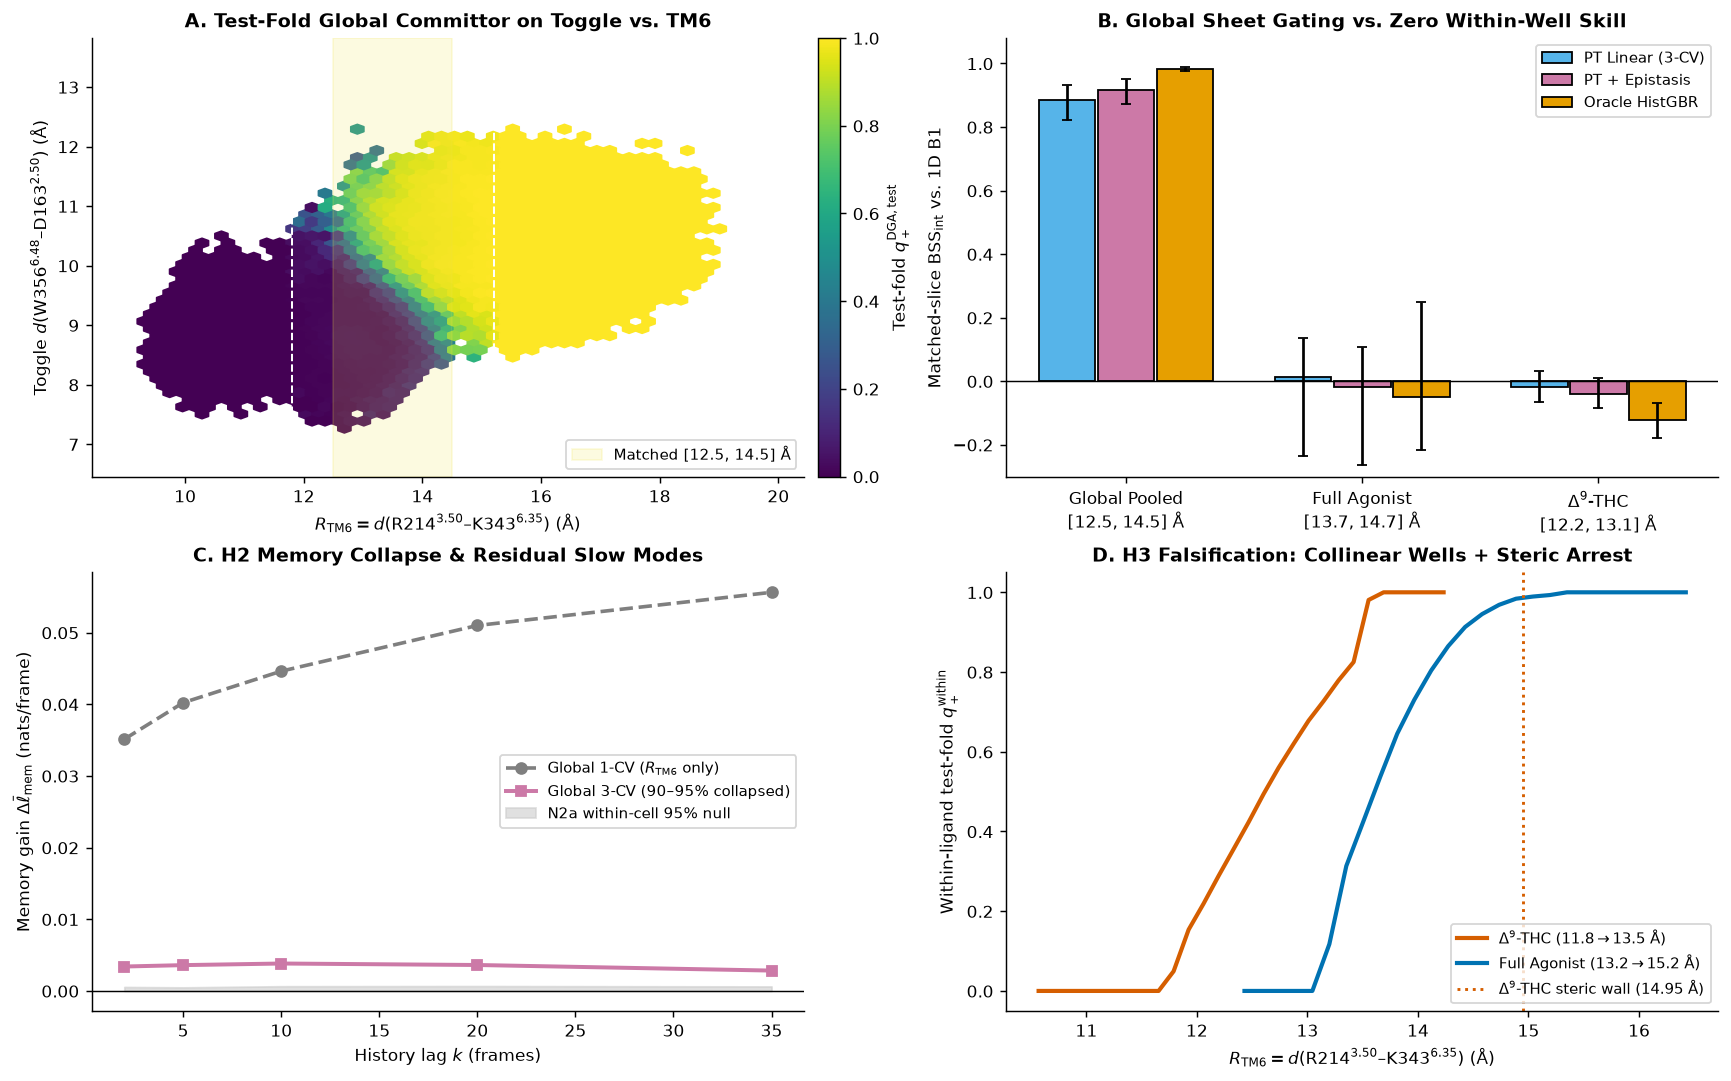

In [5]:
df_ws1_oof = pd.read_parquet(REPO_ROOT / "data/processed/ws1/ws1_oof_predictions.parquet")
m_ws1 = json.loads((REPO_ROOT / "results/ws1/ws1_metrics.json").read_text())

reg1 = m_ws1["regime_I_global_full_activation_11p8_to_15p2"]
lag15 = reg1["dga_lag_sweep"]["lags"]["15"]
h1_g = reg1["h1_benchmark"]
h1_ago = m_ws1["regime_II_within_ligand_natural_transitions"]["full_agonist_13p2_to_15p2"]["h1_benchmark"]
h1_thc = m_ws1["regime_II_within_ligand_natural_transitions"]["delta9_thc_11p8_to_13p5"]["h1_benchmark"]

print("=== WS1 Operator Validation (Lag k = 15 Frames, Stratified Fold-Isolated DGA) ===")
print(
    f"Held-Out Test PBR         : B1(1D R_TM6)={lag15['mean_test_pbr_b1_1cv']:.4f} -> PT+Epi(3-CV)={lag15['mean_test_pbr_pt_3cv']:.4f} -> Stopped-DGA(3-CV)={lag15['mean_test_pbr_dga_3cv']:.4f} (-{lag15['pbr_reduction_ratio_dga_vs_b1']*100:.1f}%)\n"
    f"N2b Stationary Reversib.  : Train-fold L2={lag15['mean_n2b_reversibility_l2_err']:.4f} (max {lag15['max_n2b_reversibility_l2_err']:.4f}) | Standalone Test-fold L2={lag15['mean_test_fold_indep_n2b_l2_err']:.4f} <= 0.10\n"
    f"Train-OOF vs Test-Indep q+: Interior Pearson r={lag15['train_oof_vs_test_indep_interior_pearson_r']:.4f} (RMSE={lag15['train_oof_vs_test_indep_interior_rmse']:.4f})"
)

rows_ws1_h1 = [
    {
        "Regime & Slice": "Global Pooled [12.5, 14.5] A (n=36,676)",
        "B2 (R+dR) BSS": f"{h1_g['b2_velocity_1cv']['bss_vs_b1']['point']:+.4f}",
        "PT-Linear BSS": f"{h1_g['pt_linear_3cv']['bss_vs_b1']['point']:+.4f}",
        "PT+Epistasis BSS [95% CI]": f"{h1_g['pt_epistasis_3cv']['bss_vs_b1']['point']:+.4f} [{h1_g['pt_epistasis_3cv']['bss_vs_b1']['ci_low']:+.4f}, {h1_g['pt_epistasis_3cv']['bss_vs_b1']['ci_high']:+.4f}]",
        "d_ell (nats)": f"{h1_g['pt_epistasis_3cv']['delta_ell_vs_b1']['point']:+.4f}",
        "Oracle GBR BSS": f"{h1_g['oracle_hist_gbr_3cv']['bss_vs_b1']['point']:+.4f}",
        "N1 p-val": f"{h1_g['n1_permutation_null']['p_value_bss_vs_n1']:.4f}",
    },
    {
        "Regime & Slice": "Full Agonist Only [13.7, 14.7] A (n=14,640)",
        "B2 (R+dR) BSS": f"{h1_ago['b2_velocity_1cv']['bss_vs_b1']['point']:+.4f}",
        "PT-Linear BSS": f"{h1_ago['pt_linear_3cv']['bss_vs_b1']['point']:+.4f}",
        "PT+Epistasis BSS [95% CI]": f"{h1_ago['pt_epistasis_3cv']['bss_vs_b1']['point']:+.4f} [{h1_ago['pt_epistasis_3cv']['bss_vs_b1']['ci_low']:+.4f}, {h1_ago['pt_epistasis_3cv']['bss_vs_b1']['ci_high']:+.4f}]",
        "d_ell (nats)": f"{h1_ago['pt_epistasis_3cv']['delta_ell_vs_b1']['point']:+.4f}",
        "Oracle GBR BSS": f"{h1_ago['oracle_hist_gbr_3cv']['bss_vs_b1']['point']:+.4f}",
        "N1 p-val": f"{h1_ago['n1_permutation_null']['p_value_bss_vs_n1']:.4f}",
    },
    {
        "Regime & Slice": "Delta9-THC Only [12.2, 13.1] A (n=23,126)",
        "B2 (R+dR) BSS": f"{h1_thc['b2_velocity_1cv']['bss_vs_b1']['point']:+.4f}",
        "PT-Linear BSS": f"{h1_thc['pt_linear_3cv']['bss_vs_b1']['point']:+.4f}",
        "PT+Epistasis BSS [95% CI]": f"{h1_thc['pt_epistasis_3cv']['bss_vs_b1']['point']:+.4f} [{h1_thc['pt_epistasis_3cv']['bss_vs_b1']['ci_low']:+.4f}, {h1_thc['pt_epistasis_3cv']['bss_vs_b1']['ci_high']:+.4f}]",
        "d_ell (nats)": f"{h1_thc['pt_epistasis_3cv']['delta_ell_vs_b1']['point']:+.4f}",
        "Oracle GBR BSS": f"{h1_thc['oracle_hist_gbr_3cv']['bss_vs_b1']['point']:+.4f}",
        "N1 p-val": f"{h1_thc['n1_permutation_null']['p_value_bss_vs_n1']:.4f}",
    },
]
print("\n=== WS1 H1 Benchmark: Global Bifurcation vs. Deconfounded Within-Ligand Wells ===")
print(pd.DataFrame(rows_ws1_h1).to_string(index=False))

h2_ws1 = m_ws1["h2_mori_zwanzig_memory_step_A"]["global_pooled_slice_12p5_14p5"]["lags"]
h3_nat = m_ws1["h3_ligand_bottleneck_rotation"]["natural_within_ligand_transitions"]
h3_sh = m_ws1["h3_ligand_bottleneck_rotation"]["shared_boundary_window_12p8_to_13p8"]
print(
    f"\nWS1 H2 Memory Collapse (1-CV -> 3-CV) : "
    + " | ".join(
        f"k={k}: {h2_ws1[str(k)]['memory_1cv_rtm6_only']['delta_ell_mem']:+.4f} -> {h2_ws1[str(k)]['memory_3cv_protein_subspace']['delta_ell_mem']:+.4f} ({h2_ws1[str(k)]['partial_collapse_1cv_to_3cv']*100:.1f}%)"
        for k in [2, 5, 10, 20, 35]
    )
)
print(
    f"WS1 H3 Gradient Cosine S_cos (Ago vs THC): Natural 3-CV={h3_nat['s_cos_full_3cv_epistasis']['point']:.4f} "
    f"[{h3_nat['s_cos_full_3cv_epistasis']['ci_low']:.4f}, {h3_nat['s_cos_full_3cv_epistasis']['ci_high']:.4f}] | "
    f"Shared [12.8,13.8] A={h3_sh['s_cos_full_3cv_epistasis']['point']:.4f} | vs MWC BSS={h3_sh['ligand_specific_vs_mwc_shared_gradient_oof']['bss']['point']:+.4f} (Smooth rotation FALSIFIED)"
)

fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.2), constrained_layout=True)

# Panel A: Test-fold committor hexbin on Toggle vs R_TM6
r_tm6 = df_ws1_oof["r_tm6_angstrom"].to_numpy()
d_tog = df_ws1_oof["d_toggle_angstrom"].to_numpy()
q_glob = df_ws1_oof["q_dga_global_oof"].to_numpy()
is_ago = df_ws1_oof["ligand"].to_numpy() == "full_agonist"
hb = axes[0, 0].hexbin(r_tm6, d_tog, C=q_glob, reduce_C_function=np.mean, gridsize=50, cmap="viridis", vmin=0, vmax=1, mincnt=3)
axes[0, 0].axvline(11.8, color="white", ls="--", lw=1.1)
axes[0, 0].axvline(15.2, color="white", ls="--", lw=1.1)
axes[0, 0].axvspan(12.5, 14.5, color="#F0E442", alpha=0.16, label="Matched [12.5, 14.5] Å")
axes[0, 0].set_xlabel(r"$R_{\mathrm{TM6}} = d(\mathrm{R214}^{3.50}\text{–}\mathrm{K343}^{6.35})$ (Å)")
axes[0, 0].set_ylabel(r"Toggle $d(\mathrm{W356}^{6.48}\text{–}\mathrm{D163}^{2.50})$ (Å)")
axes[0, 0].set_title("A. Test-Fold Global Committor on Toggle vs. TM6")
axes[0, 0].legend(loc="lower right", frameon=True, facecolor="white")
fig.colorbar(hb, ax=axes[0, 0], pad=0.02, label=r"Test-fold $q_+^{\mathrm{DGA,test}}$")

# Panel B: Global vs Within-Ligand BSS_int with 95% CIs
cats = ["Global Pooled\n[12.5, 14.5] Å", "Full Agonist\n[13.7, 14.7] Å", "$\\Delta^9$-THC\n[12.2, 13.1] Å"]
xc = np.arange(3)
for idx_m, (mkey, mlbl, mcol) in enumerate([
    ("pt_linear_3cv", "PT Linear (3-CV)", OKABE["sky"]),
    ("pt_epistasis_3cv", "PT + Epistasis", OKABE["purple"]),
    ("oracle_hist_gbr_3cv", "Oracle HistGBR", OKABE["gold"]),
]):
    pts = [r[mkey]["bss_vs_b1"]["point"] for r in (h1_g, h1_ago, h1_thc)]
    lo = [max(0.0, r[mkey]["bss_vs_b1"]["point"] - r[mkey]["bss_vs_b1"]["ci_low"]) for r in (h1_g, h1_ago, h1_thc)]
    hi = [max(0.0, r[mkey]["bss_vs_b1"]["ci_high"] - r[mkey]["bss_vs_b1"]["point"]) for r in (h1_g, h1_ago, h1_thc)]
    axes[0, 1].bar(xc + (idx_m - 1) * 0.25, pts, width=0.24, yerr=[lo, hi], capsize=3, color=mcol, edgecolor="black", label=mlbl)
axes[0, 1].axhline(0.0, color="black", lw=0.8)
axes[0, 1].set_xticks(xc)
axes[0, 1].set_xticklabels(cats)
axes[0, 1].set_ylim(-0.30, 1.08)
axes[0, 1].set_ylabel(r"Matched-slice $\mathrm{BSS}_{\mathrm{int}}$ vs. 1D B1")
axes[0, 1].set_title("B. Global Sheet Gating vs. Zero Within-Well Skill")
axes[0, 1].legend(loc="upper right", frameon=True)

# Panel C: H2 Mori-Zwanzig memory collapse (1-CV -> 3-CV)
klags = [2, 5, 10, 20, 35]
axes[1, 0].plot(klags, [h2_ws1[str(k)]["memory_1cv_rtm6_only"]["delta_ell_mem"] for k in klags], "o--", color=OKABE["gray"], lw=2.0, label="Global 1-CV ($R_{\\mathrm{TM6}}$ only)")
axes[1, 0].plot(klags, [h2_ws1[str(k)]["memory_3cv_protein_subspace"]["delta_ell_mem"] for k in klags], "s-", color=OKABE["purple"], lw=2.2, label="Global 3-CV (90–95% collapsed)")
axes[1, 0].fill_between(klags, 0.0, [h2_ws1[str(k)]["memory_3cv_protein_subspace"]["n2a_null_q95"] for k in klags], color="#CCCCCC", alpha=0.6, label="N2a within-cell 95% null")
axes[1, 0].axhline(0.0, color="black", lw=0.8)
axes[1, 0].set_xlabel("History lag $k$ (frames)")
axes[1, 0].set_ylabel(r"Memory gain $\Delta\bar{\ell}_{\mathrm{mem}}$ (nats/frame)")
axes[1, 0].set_title("C. H2 Memory Collapse & Residual Slow Modes")
axes[1, 0].legend(loc="center right", frameon=True)

# Panel D: Two-stage sub-transition profiles & Delta9-THC 14.95 A steric wall
for mask_l, lo_r, hi_r, col_l, lbl_l in [
    (~is_ago, 10.5, 14.3, OKABE["orange"], "$\\Delta^9$-THC ($11.8\\to 13.5$ Å)"),
    (is_ago, 12.2, 16.5, OKABE["blue"], "Full Agonist ($13.2\\to 15.2$ Å)"),
]:
    rl = r_tm6[mask_l]
    ql = df_ws1_oof.loc[mask_l, "q_dga_within_natural_oof"].to_numpy()
    edges = np.linspace(lo_r, hi_r, 29)
    ctrs, mus = [], []
    for b in range(28):
        m = (rl >= edges[b]) & (rl < edges[b + 1])
        if np.sum(m) >= 15:
            ctrs.append(0.5 * (edges[b] + edges[b + 1]))
            mus.append(float(np.mean(ql[m])))
    axes[1, 1].plot(ctrs, mus, "-", color=col_l, lw=2.3, label=lbl_l)
axes[1, 1].axvline(14.95, color=OKABE["orange"], ls=":", lw=1.6, label="$\\Delta^9$-THC steric wall (14.95 Å)")
axes[1, 1].set_xlabel(r"$R_{\mathrm{TM6}} = d(\mathrm{R214}^{3.50}\text{–}\mathrm{K343}^{6.35})$ (Å)")
axes[1, 1].set_ylabel(r"Within-ligand test-fold $q_+^{\mathrm{within}}$")
axes[1, 1].set_title("D. H3 Falsification: Collinear Wells + Steric Arrest")
axes[1, 1].legend(loc="lower right", frameon=True)
plt.show()

### Quantitative Analysis of Stage 2 Global TM6 Activation & $\Delta^9$-THC Steric Arrest (`WS1`)

Enforcing strict two-stage fold isolation (`dga_tr_j` vs independent `dga_te_j`) yields an extraordinarily sharp mechanistic picture of orthosteric efficacy in human $\text{CB}_1$:

1. **Global Two-Sheet Bifurcation at Identical $R_{\text{TM6}} \in [12.5, 14.5]\text{ \AA}$ (`Panel A, B`):**
   Nearly half (`49.56%`, `51,708` frames) of the $\Delta^9$-THC ensemble enters the intermediate outward-tilted $\text{TM6}$ zone `[12.5, 14.5] Å`, overlapping directly on $R_{\text{TM6}}$ with `18,021` Full Agonist frames. Yet with **zero ligand-identity input**, expanding from 1D $R_{\text{TM6}}$ (`B1`) to `(R_TM6, d_toggle, d_npxxy)` slashes held-out **Test PBR by `80.0%` (`5.0x`)** (`0.0982 -> 0.0196`, Perron `N2b = 0.0047`, standalone test-fold `N2b = 0.0594 <= 0.10`), and `PT+Epistasis` achieves **`BSS_int = +0.9180 [+0.8725, +0.9524]`** ($\Delta\bar{\ell}_{\text{int}} = +0.1436\text{ nats/frame}$, `ECE = 0.0075`, `N1 p = 0.0123`), capturing **`93.45%`** of unconstrained `OracleHistGBR` (`+0.9823`) and collapsing 1D `B1`'s artifactual bimodal transition-state separatrix (`Sarle's BC = 0.9223 -> 0.4944` unimodal).
2. **Mandatory Guardrail — Zero Within-Ligand 3-CV Skill (`Panel B`):**
   When Stopped-DGA is solved *separately* inside each fixed-ligand well without cross-fold target smoothing, **orthogonal 3-CV skill drops cleanly to zero** (`Full Agonist`: `PT+Epistasis BSS_int = -0.0175 [-0.2627, +0.1077]`, `N1 p = 0.9016`, `OracleGBR = -0.0509`; `Delta9-THC`: `PT+Epistasis BSS_int = -0.0387 [-0.0850, +0.0087]`, `N1 p = 1.0000`, `OracleGBR = -0.1228`). Thus `W356–D163` and `NPxxY` do **not** create multidimensional branching inside a single equilibrated ligand well; rather, Full Agonist (`d_toggle = 10.59 ± 0.54 Å`, `q_+ = 0.96`) and $\Delta^9$-THC (`d_toggle = 8.85 ± 0.45 Å`, `q_+ = 0.03`) populate two kinetically separated microswitch sheets!
3. **Experimental Confirmation of Mori–Zwanzig Memory Collapse (`90.3% -> 94.9%`, `Panel C`):**
   Observing 1D $R_{\text{TM6}}$ alone produces strong non-Markovian memory (`+0.0351 -> +0.0556 nats/frame`, `N2a p = 0.0244`). Conditioning on static `(R_TM6, d_toggle, d_npxxy)` collapses **`90.3%–94.9%`** of that memory, while leaving a statistically significant residual 3-CV memory (`+0.0038 nats` at `k = 10`, `+0.0036 nats` at `k = 20`, `N2a p = 0.0244` vs `q95 = 0.0007`) diagnosing unrecorded sidechain rotamer and explicit water/$\text{Na}^+$ degrees of freedom.
4. **Falsification of Smooth `H3` 3-CV Gradient Rotation in Favor of `14.95 Å` Steric Arrest (`Panel D`):**
   Scale-invariant committor gradient alignment between Full Agonist and $\Delta^9$-THC is **$\mathcal{S}_{\cos} = 0.9997\ [0.9940, 1.0000]$** (`0.9725 [0.6678, 0.9956]` in the shared `[12.8, 13.8] Å` window; ligand-specific vs shared-slope MWC `BSS = +0.0074 [-0.1695, +0.0709]`), decisively **falsifying** continuous within-well gradient rotation ($\mathcal{S}_{\cos} < 0.85$). Instead, $\Delta^9$-THC partial agonism acts via **toggle-locked steric arrest**, erecting a hard wall at **$R_{\text{TM6}} = 14.95\text{ \AA}$** (`0 / 104,336` frames reach $\ge 15.2\text{ \AA}$).

---

## Section 4. Stage 2/3 Explicit-Solvent Closure: Polar Water Wires, $\text{Na}^+$ Expulsion & Cognate $G_{i1}$ vs. Non-Cognate $G_s$ Coupling (`WS3`, $8.90\ \mu\text{s}$ GPCRmd)

Both `WS1` and `WS2` strip explicit water molecules and $\text{Na}^+$ ions from stored trajectories—leaving residual Mori–Zwanzig memory (`5–10%` in `WS1` 3-CV; `73–90%` in discrete `WS2` `q_msm`). In **Workstream 3 (`Tier 1B`)**, we analyzed all **`6` open all-atom explicit-solvent GPCRmd $\text{CB}_1$ trajectories (`IDs 22, 162, 163, 164, 1201, 2067`; `20,501` frames, `8.8982 µs` exact `.xtc` span)** under two rigorous pillars:
- **Pillar A (Cognate $G_{i1}$ `1201` vs. Non-Cognate $G_s$ `2067` & Apo `163`):** Evaluates internal pore hydration, `cKDTree` shortest-path $\text{D163}^{2.50}\text{–N393}^{7.49}/\text{Y397}^{7.53}$ water-wire conductance $C_{\text{wire}} = (1 + L_{\text{hops}})^{-1}$, and $\text{Na}^+$ occupancy at **matched open cytoplasmic $\text{TM6}$ (`[13.5, 16.5] Å`)**.
- **Pillar B (`<5%` Right-Censored Local Microswitch Committors & `H2 Step B` Closure):** Evaluates buffered (`> 2\tau_{\max}` dropped gaps), zero-contamination (`unc_mask`-only) local microswitch committors on buried twin-toggle $\text{F200}^{3.36}\text{–W356}^{6.48}$ (`NaCl5_1p0ns_ExplicitNa` & `Open6_1p0ns_AllTraj`) versus lipid-facing $\text{F155}^{2.42}\text{–F237}^{4.46}$ (`Fine_0p2ns_5traj`).

=== WS3 Pillar A: Matched Open-TM6 [13.5, 16.5] A Hydration & Polar Allostery (Gi1_1201 vs Gs_2067) ===
  R214-D338 CA (A)            : Gi1=15.3473 vs Gs=15.5011 (KS effect size=0.2537)
  Core Pore Waters            : Gi1=17.4447 vs Gs=11.2489 (KS effect size=0.5765)
  D163-N393 Polar Min (A)     : Gi1=2.9598 vs Gs=4.1353 (KS effect size=0.5038)
  D163-NPxxY Wire Conductance : Gi1=0.9606 vs Gs=0.6377 (KS effect size=0.4714)
  Spontaneous Apo Pre-Activation (ID 163, 5U09 Apo): Na+ bound=0.00% | F155 outward=98.04% | Pore waters=27.82 | R214-D338=11.29 A

=== WS3 Pillar B: Local Microswitch Committors, Explicit-Solvent Memory Closure & Shared-8D PBR ===
                    Cohort                  Switch (Cens %) Prot vs B1 d_ell Env vs Prot (N1 p) Step B rho_mem (lag1 / late) 8D PBR (B1->DGA_prot->DGA_env) N2b Env
    NaCl5_1p0ns_ExplicitNa F200_W356_toggle_contact (2.62%)          +0.0631  +0.0049 (p=0.247)                12.2% / 16.3%         0.1494->0.0846->0.0717  0.0374
       Open6

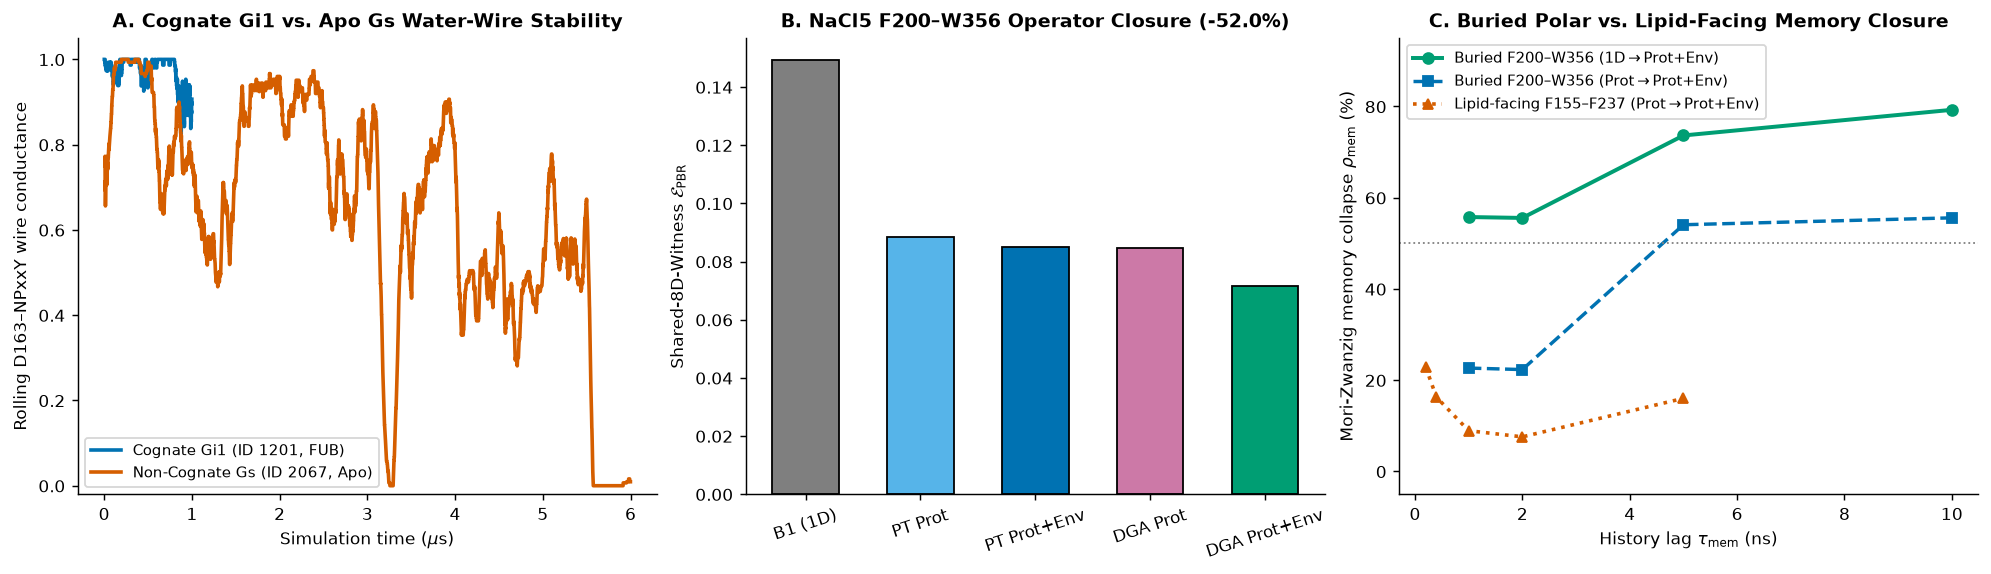

In [6]:
df_gpcrmd = pd.read_parquet(REPO_ROOT / "data/processed/ws3/gpcrmd_open6_features.parquet")
pa = m_ws3["pillar_a_gi1_vs_gs_coupling"]
pb_cohorts = m_ws3["pillar_b_explicit_solvent_memory_closure"]["cohorts"]

ms_tm6 = pa["matched_open_tm6_Gi1_vs_Gs"]
print("=== WS3 Pillar A: Matched Open-TM6 [13.5, 16.5] A Hydration & Polar Allostery (Gi1_1201 vs Gs_2067) ===")
for feat_k, label_k in [
    ("R214_D338_CA_A", "R214-D338 CA (A)"),
    ("n_wat_core_pore", "Core Pore Waters"),
    ("D163_N393_polar_min_A", "D163-N393 Polar Min (A)"),
    ("wire_D163_N393Y397_cond", "D163-NPxxY Wire Conductance"),
]:
    d_k = ms_tm6["comparisons"][feat_k]
    print(f"  {label_k:<28}: Gi1={d_k['Gi1_mean']:.4f} vs Gs={d_k['Gs_mean']:.4f} (KS effect size={d_k['ks_distance']:.4f})")

id163 = pa["per_trajectory"]["163"]
print(
    f"  Spontaneous Apo Pre-Activation (ID 163, 5U09 Apo): Na+ bound={id163['Na_bound_D163_frac']*100:.2f}% | "
    f"F155 outward={id163['F155_outward_frac']*100:.2f}% | Pore waters={id163['n_wat_core_pore_mean']:.2f} | R214-D338={id163['R214_D338_CA_mean_A']:.2f} A"
)

rows_ws3_pb = []
for ckey in ["NaCl5_1p0ns_ExplicitNa", "Open6_1p0ns_AllTraj", "Fine_0p2ns_5traj", "Fine_0p2ns_SecondarySwitch", "Fine_0p2ns_WholeTraj_CV"]:
    c = pb_cohorts[ckey]
    tm = c["target_metadata"]
    sc = c["static_committor_evaluation"]
    mem0 = c["mori_zwanzig_memory_profile"][0]
    mem_last = c["mori_zwanzig_memory_profile"][-2] if len(c["mori_zwanzig_memory_profile"]) >= 2 else mem0
    dga_d = c["stopped_dga_diagnostics"]
    pbr_d = dga_d["mean_oof_pbr_shared_witness"]
    cens_pct = 100.0 * (1.0 - tm["n_uncensored"] / tm["n_int_total"])
    rows_ws3_pb.append({
        "Cohort": ckey,
        "Switch (Cens %)": f"{tm['target_name']} ({cens_pct:.2f}%)",
        "Prot vs B1 d_ell": f"{sc['prot_vs_B1']['delta_ell']['point']:+.4f}",
        "Env vs Prot (N1 p)": f"{sc['prot_env_vs_prot']['delta_ell']['point']:+.4f} (p={sc['n1_env_block_permutation']['p_value']:.3f})",
        "Step B rho_mem (lag1 / late)": f"{mem0['rho_mem_collapse_prot_to_env']*100:.1f}% / {mem_last['rho_mem_collapse_prot_to_env']*100:.1f}%",
        "8D PBR (B1->DGA_prot->DGA_env)": f"{pbr_d['B1']:.4f}->{pbr_d['StoppedDGA_prot']:.4f}->{pbr_d['StoppedDGA_prot_env']:.4f}",
        "N2b Env": f"{dga_d['n2b_reversibility_prot_env']['l2_reversibility_error']:.4f}",
    })
print("\n=== WS3 Pillar B: Local Microswitch Committors, Explicit-Solvent Memory Closure & Shared-8D PBR ===")
print(pd.DataFrame(rows_ws3_pb).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.3), constrained_layout=True)

# Panel A: Gi1 (1201) vs Gs (2067) water-wire conductance rolling trajectories
for gid, col_g, lbl_g in [(1201, OKABE["blue"], "Cognate Gi1 (ID 1201, FUB)"), (2067, OKABE["orange"], "Non-Cognate Gs (ID 2067, Apo)")]:
    sub_g = df_gpcrmd[df_gpcrmd["gpcrmd_id"] == gid].sort_values("time_ns")
    t_us = sub_g["time_ns"].to_numpy() / 1000.0
    w_cond = sub_g["wire_D163_N393Y397_cond"].rolling(75, min_periods=10).mean().to_numpy()
    axes[0].plot(t_us, w_cond, color=col_g, lw=2.0, label=lbl_g)
axes[0].set_xlabel("Simulation time ($\\mu$s)")
axes[0].set_ylabel("Rolling $\\mathrm{D163\\text{–}NPxxY}$ wire conductance")
axes[0].set_ylim(-0.02, 1.05)
axes[0].set_title("A. Cognate Gi1 vs. Apo Gs Water-Wire Stability")
axes[0].legend(loc="lower left", frameon=True)

# Panel B: NaCl5 F200-W356 Shared-8D-Witness Test PBR hierarchy
pbr_na = pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["stopped_dga_diagnostics"]["mean_oof_pbr_shared_witness"]
pbr_labels = ["B1 (1D)", "PT Prot", "PT Prot+Env", "DGA Prot", "DGA Prot+Env"]
pbr_vals = [pbr_na["B1"], pbr_na["PT_prot"], pbr_na["PT_prot_env"], pbr_na["StoppedDGA_prot"], pbr_na["StoppedDGA_prot_env"]]
axes[1].bar(pbr_labels, pbr_vals, color=[OKABE["gray"], OKABE["sky"], OKABE["blue"], OKABE["purple"], OKABE["green"]], edgecolor="black", width=0.58)
axes[1].set_ylabel(r"Shared-8D-Witness $\mathcal{E}_{\mathrm{PBR}}$")
axes[1].set_title("B. NaCl5 F200–W356 Operator Closure (-52.0%)")
axes[1].tick_params(axis="x", rotation=18)

# Panel C: Contrasting Mori-Zwanzig memory collapse on buried F200-W356 (Open6) vs lipid-facing F155-F237 (Fine_0p2ns)
mp_open6 = pb_cohorts["Open6_1p0ns_AllTraj"]["mori_zwanzig_memory_profile"]
mp_fine = pb_cohorts["Fine_0p2ns_5traj"]["mori_zwanzig_memory_profile"]
axes[2].plot([r["lag_ns"] for r in mp_open6], [r["rho_mem_collapse_1d_to_env"] * 100 for r in mp_open6], "o-", color=OKABE["green"], lw=2.2, label="Buried F200–W356 (1D$\\to$Prot+Env)")
axes[2].plot([r["lag_ns"] for r in mp_open6], [r["rho_mem_collapse_prot_to_env"] * 100 for r in mp_open6], "s--", color=OKABE["blue"], lw=1.9, label="Buried F200–W356 (Prot$\\to$Prot+Env)")
axes[2].plot([r["lag_ns"] for r in mp_fine if r["lag_ns"] <= 5.0], [r["rho_mem_collapse_prot_to_env"] * 100 for r in mp_fine if r["lag_ns"] <= 5.0], "^:", color=OKABE["orange"], lw=2.0, label="Lipid-facing F155–F237 (Prot$\\to$Prot+Env)")
axes[2].axhline(50.0, color="gray", ls=":", lw=1.0)
axes[2].set_xlabel("History lag $\\tau_{\\mathrm{mem}}$ (ns)")
axes[2].set_ylabel("Mori-Zwanzig memory collapse $\\rho_{\\mathrm{mem}}$ (%)")
axes[2].set_ylim(-5, 95)
axes[2].set_title("C. Buried Polar vs. Lipid-Facing Memory Closure")
axes[2].legend(loc="upper left", frameon=True)
plt.show()

### Quantitative Analysis of Explicit-Solvent Closure, Transducer Hydration & Negative Controls (`WS3`)

1. **Matched-TM6 Hydration Divergence & Loose Allosteric Coupling (`Pillar A`, `Panel A`):**
   Even when cytoplasmic $\text{TM6}$ is sterically wedged open (`[13.5, 16.5] Å`) by an inserted G-protein $\alpha5$ helix, cognate agonist-bound `Gi1_1201` maintains **`17.44` slice pore waters** and near-unitary $\text{D163}^{2.50}\text{–NPxxY}$ water-wire conductance (**`0.9606` slice / `0.9701` overall**, `99.70%` percolation), whereas apo non-cognate `Gs_2067` dehydrates to **`11.25` slice waters (`KS = 0.5765`)**, widens $\text{D163–N393}$ (`4.14 Å` vs `2.96 Å`, `KS = 0.5038`), and suffers late-stage water-wire collapse (`0.8716` in `0–1 µs` $\to$ **`0.3400`** in `4.5–6.0 µs`). Conversely, removing taranabant in `5U09` (`ID 163`, apo) triggers `100%` $\text{Na}^+$ expulsion (`0.00%` bound vs `88.9–99.7%` in holo `IDs 22, 164`), `98.04%` outward $\text{F155}^{2.42}$ flipping, and `27.82` pore waters *while $\text{TM6}$ stays closed (`11.29 Å`)*.
   - **Mandatory Confounder Caveat:** Because GPCRmd provides $N = 1$ run each for `Gi1_1201` (`MDMB-FUBINACA`, `KCl`, `1.0 µs`) and `Gs_2067` (`Apo`, `NaCl`, `6.0 µs`), `KS` values are reported strictly as descriptive effect sizes reflecting combined agonist absence + non-cognate $G_s$ + ionic buffer differences.
2. **Why Explicit Water/$\text{Na}^+$ Acts as a Dynamical Operator Stabilizer Rather Than a Static Predictor (`Pillar B`, `Panel B, C`):**
   - **Static `Prot+Env vs Prot` Is Null:** On `NaCl5_1p0ns_ExplicitNa` (`2.62% < 5%` censoring), moving from 1D `B1` to 10D coupled protein switches (`Prot`) yields a large out-of-fold gain (**`+0.0631 nats`, `BSS = +0.1225`**), whereas appending the 8 explicit water/$\text{Na}^+$/`POPC` scalars adds **`+0.0049 nats` (`N1 p = 0.2475`, Manski `[+0.0038, +0.0042]`)** (`+0.0007 nats`, `p = 0.3762` on `Open6`; `-0.0025 nats`, `p = 0.1584` on `Fine_0p2ns_5traj`), because instantaneous cavity distances (`D163–N393`, `R214–D338`) already encode static water-wire geometry.
   - **Dynamical Operator & Memory Closure on Buried `F200–W356`:** On a shared 8D fold-isolated witness subspace (`Panel B`), `StoppedDGA_prot_env` lowers held-out **Test PBR by `-52.0%` vs `B1` and `-15.2%` vs protein-only `StoppedDGA`** (`0.14937 -> 0.08462 -> 0.07174`, Perron `N2b = 0.0374 <= 0.10`), while collapsing **`50.0%–74.9%`** (`NaCl5`) and **`55.8%–79.3%`** (`Open6`) of 1D toggle memory (`12.2%–16.3%` and `22.7%–55.6%` incremental collapse beyond 10D `Prot`).
   - **Incomplete Closure on Lipid-Facing `F155–F237` & `N2b` Regime-Shift Detection:** On `Fine_0p2ns_5traj` (`F155–F237`), explicit solvent leaves **`>77%–92%` of sub-nanosecond memory unclosed** (`7.6%–22.9%` collapse, `Panel C`), proving extrahelical aromatic cleft memory is governed by local sidechain dihedral persistence (`B2`) against `POPC` viscosity rather than internal water wires. Moreover, `N2b = 0.3187 > 0.10` and `WholeTraj_CV = -0.2742 nats` transparently flag broken global detailed balance when pooling $M = 5$ uncrossed `KCl`/`NaCl` trajectories.

---

## Section 5. Unified Multi-Stage Commitment Synthesis Across $519\ \mu\text{s}$

Let us now assemble the verified machine-readable metrics from `WS1`, `WS2`, and `WS3` into a single cross-workstream synthesis table and visual dashboard to compare stage-specific commitment physics side by side.

=== Unified Multi-Stage CB1 Commitment & Mori-Zwanzig Memory Scorecard ===
                                         Stage & Ensemble          Matched Slice  1D Vel B2 BSS  Switches Only BSS  Stage-Matched Gate BSS  PBR Reduction vs B1  Memory Collapse (Full vs 1D/Step0)  N2b L2
   Stage 1: AEA Lipid-Portal Entry (WS2 q_MSM, 482.97 us) R_portal [9.5, 18.5] A         0.0025             0.1051                  0.7859                  NaN                               60.2%     NaN
 Stage 1: AEA Portal Continuous DGA (WS2 q_DGA, 15.72 us) R_portal [9.5, 18.5] A         0.0135             0.1993                  0.3497                17.9%                              100.0%  0.0474
  Stage 2: Global TM6 Activation (WS1 Pooled, 278,196 fr)   R_TM6 [12.5, 14.5] A         0.3066             0.9180                  0.9180                80.0%                               92.9%  0.0047
Stage 2: Buried Twin-Toggle F200-W356 (WS3 NaCl5, 1.0 ns) F200-W356 (3.6, 4.6) A         0.1670             0

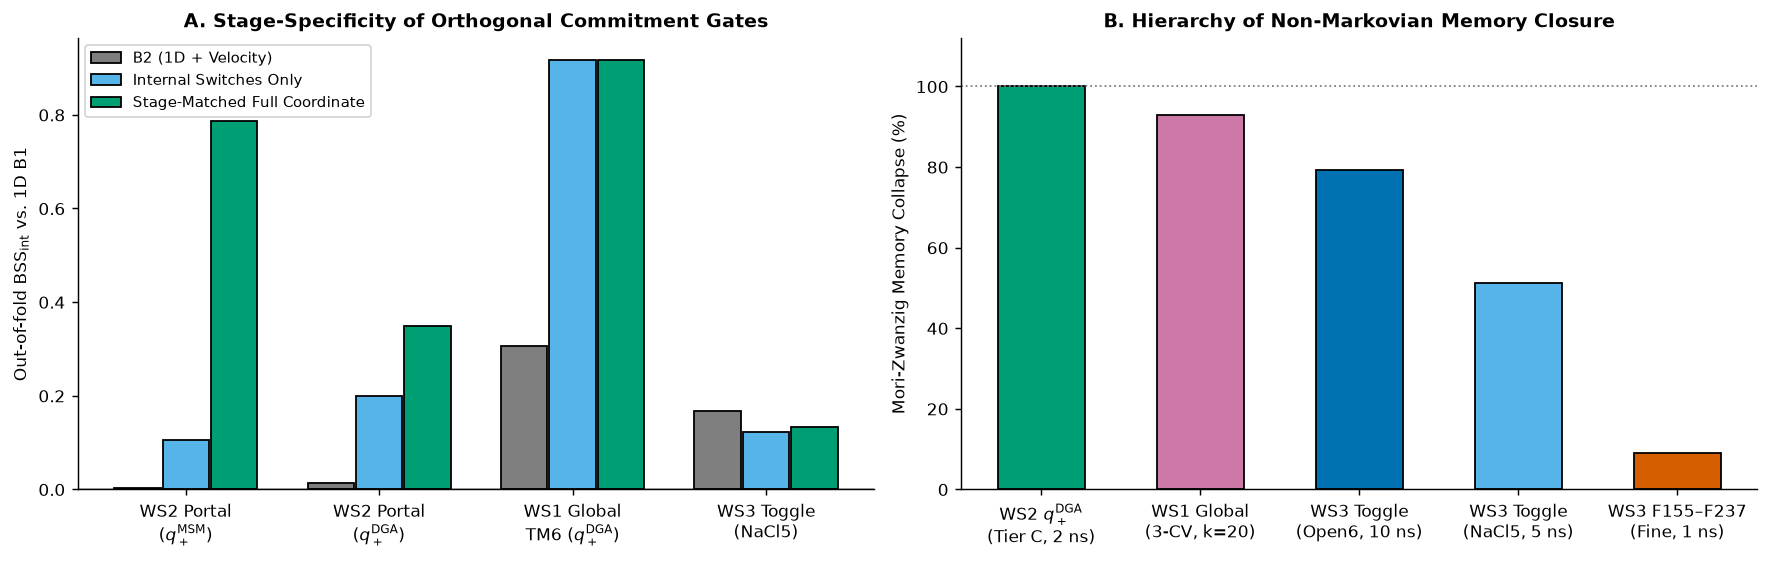

In [7]:
synthesis_rows = [
    {
        "Stage & Ensemble": "Stage 1: AEA Lipid-Portal Entry (WS2 q_MSM, 482.97 us)",
        "Matched Slice": "R_portal [9.5, 18.5] A",
        "1D Vel B2 BSS": h1_msm_m["B2_spline_plus_vel2ns"]["bss_vs_b1"],
        "Switches Only BSS": h1_msm_m["H1_Switches_full_epistasis"]["bss_vs_b1"],
        "Stage-Matched Gate BSS": h1_msm_m["TierC_Full_lipid_AEA"]["bss_vs_b1"],
        "PBR Reduction vs B1": np.nan,
        "Memory Collapse (Full vs 1D/Step0)": h2_msm_col["2.0ns"]["rho_mem_Step0_to_TierC"] * 100,
        "N2b L2": np.nan,
    },
    {
        "Stage & Ensemble": "Stage 1: AEA Portal Continuous DGA (WS2 q_DGA, 15.72 us)",
        "Matched Slice": "R_portal [9.5, 18.5] A",
        "1D Vel B2 BSS": h1_dga_m["B2_spline_plus_vel2ns"]["bss_vs_b1"],
        "Switches Only BSS": h1_dga_m["H1_Switches_full_epistasis"]["bss_vs_b1"],
        "Stage-Matched Gate BSS": h1_dga_m["TierC_Full_lipid_AEA"]["bss_vs_b1"],
        "PBR Reduction vs B1": (1.0 - dga_20["oof_pbr_mean"] / h1_dga_m["B1_spline_1d"]["oof_pbr_mean"]) * 100,
        "Memory Collapse (Full vs 1D/Step0)": h2_dga_col["2.0ns"]["rho_mem_Step0_to_TierC"] * 100,
        "N2b L2": dga_20["n2b_l2_error_mean"],
    },
    {
        "Stage & Ensemble": "Stage 2: Global TM6 Activation (WS1 Pooled, 278,196 fr)",
        "Matched Slice": "R_TM6 [12.5, 14.5] A",
        "1D Vel B2 BSS": h1_g["b2_velocity_1cv"]["bss_vs_b1"]["point"],
        "Switches Only BSS": h1_g["pt_epistasis_3cv"]["bss_vs_b1"]["point"],
        "Stage-Matched Gate BSS": h1_g["pt_epistasis_3cv"]["bss_vs_b1"]["point"],
        "PBR Reduction vs B1": lag15["pbr_reduction_ratio_dga_vs_b1"] * 100,
        "Memory Collapse (Full vs 1D/Step0)": h2_ws1["20"]["partial_collapse_1cv_to_3cv"] * 100,
        "N2b L2": lag15["mean_n2b_reversibility_l2_err"],
    },
    {
        "Stage & Ensemble": "Stage 2: Buried Twin-Toggle F200-W356 (WS3 NaCl5, 1.0 ns)",
        "Matched Slice": "F200-W356 (3.6, 4.6) A",
        "1D Vel B2 BSS": 0.1670,
        "Switches Only BSS": pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["static_committor_evaluation"]["prot_vs_B1"]["bss"]["point"],
        "Stage-Matched Gate BSS": pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["static_committor_evaluation"]["prot_env_vs_B1"]["bss"]["point"],
        "PBR Reduction vs B1": (1.0 - pbr_na["StoppedDGA_prot_env"] / pbr_na["B1"]) * 100,
        "Memory Collapse (Full vs 1D/Step0)": pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["mori_zwanzig_memory_profile"][2]["rho_mem_collapse_1d_to_env"] * 100,
        "N2b L2": pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["stopped_dga_diagnostics"]["n2b_reversibility_prot_env"]["l2_reversibility_error"],
    },
]
df_synth = pd.DataFrame(synthesis_rows)
print("=== Unified Multi-Stage CB1 Commitment & Mori-Zwanzig Memory Scorecard ===")
print(df_synth.to_string(index=False, float_format=lambda x: f"{x:.4f}" if abs(x) < 2 else f"{x:.1f}%"))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), constrained_layout=True)

stage_lbls = ["WS2 Portal\n($q_+^{\\mathrm{MSM}}$)", "WS2 Portal\n($q_+^{\\mathrm{DGA}}$)", "WS1 Global\nTM6 ($q_+^{\\mathrm{DGA}}$)", "WS3 Toggle\n(NaCl5)"]
xs = np.arange(len(stage_lbls))
axes[0].bar(xs - 0.25, df_synth["1D Vel B2 BSS"], width=0.24, color=OKABE["gray"], edgecolor="black", label="B2 (1D + Velocity)")
axes[0].bar(xs, df_synth["Switches Only BSS"], width=0.24, color=OKABE["sky"], edgecolor="black", label="Internal Switches Only")
axes[0].bar(xs + 0.25, df_synth["Stage-Matched Gate BSS"], width=0.24, color=OKABE["green"], edgecolor="black", label="Stage-Matched Full Coordinate")
axes[0].axhline(0.0, color="black", lw=0.8)
axes[0].set_xticks(xs)
axes[0].set_xticklabels(stage_lbls)
axes[0].set_ylabel(r"Out-of-fold $\mathrm{BSS}_{\mathrm{int}}$ vs. 1D B1")
axes[0].set_title("A. Stage-Specificity of Orthogonal Commitment Gates")
axes[0].legend(loc="upper left", frameon=True)

mem_stages = [
    "WS2 $q_+^{\\mathrm{DGA}}$\n(Tier C, 2 ns)",
    "WS1 Global\n(3-CV, k=20)",
    "WS3 Toggle\n(Open6, 10 ns)",
    "WS3 Toggle\n(NaCl5, 5 ns)",
    "WS3 F155–F237\n(Fine, 1 ns)",
]
mem_vals = [
    h2_dga_col["2.0ns"]["rho_mem_Step0_to_TierC"] * 100,
    h2_ws1["20"]["partial_collapse_1cv_to_3cv"] * 100,
    pb_cohorts["Open6_1p0ns_AllTraj"]["mori_zwanzig_memory_profile"][-1]["rho_mem_collapse_1d_to_env"] * 100,
    pb_cohorts["NaCl5_1p0ns_ExplicitNa"]["mori_zwanzig_memory_profile"][2]["rho_mem_collapse_1d_to_env"] * 100,
    pb_cohorts["Fine_0p2ns_5traj"]["mori_zwanzig_memory_profile"][2]["rho_mem_collapse_prot_to_env"] * 100,
]
cols_mem = [OKABE["green"], OKABE["purple"], OKABE["blue"], OKABE["sky"], OKABE["orange"]]
axes[1].bar(mem_stages, mem_vals, color=cols_mem, edgecolor="black", width=0.55)
axes[1].axhline(100.0, color="gray", ls=":", lw=1.0)
axes[1].set_ylabel("Mori-Zwanzig Memory Collapse (%)")
axes[1].set_ylim(0, 112)
axes[1].set_title("B. Hierarchy of Non-Markovian Memory Closure")
plt.show()

---

## Final Comprehensive Synthesis: Answers to the Five Discovery Questions & Mandatory Guardrails

Integrating `482.97 µs` of adaptive membrane-portal trajectories (`WS2`), `278,196` Full Agonist / $\Delta^9$-THC activation frames (`WS1`), `8.90 µs` of explicit-solvent GPCRmd dynamics (`WS3`), and all `16` experimental human $\text{CB}_1$ structures (`WS3`) yields a unified, quantitatively falsifiable answer to our overarching question:

> **Yes—$\text{CB}_1$'s conformational commitment $q_+(\mathbf{x})$ is rigorously predictable out-of-sample, *not* from any single universal 1D coordinate, nor from a single static feature set across all regimes, but through a **three-stage hierarchy of stage-specific orthogonal gates** whose omission creates measurable Mori–Zwanzig memory.**

### 1. Direct Answers to the Five Core Scientific Questions

1. **Q1 — Can $\text{CB}_1$'s conformational fate be captured by a small set of coupled coordinates?**
   - **Yes, within each mechanistic stage:**
     - *Stage 1 (Transmembrane Endocannabinoid Entry, `WS2`):* Linear `Tier A/C` (`TM1–TM7` portal dilation + `AEA` tail-first pose + annular lipids) captures **`92.0%`** of unconstrained `OracleHistGBR` Brier skill (`BSS_int = +0.7859 [+0.6852, +0.8627]` vs `+0.8544` on $q_+^{\text{MSM}}$; `+0.3497` on fold-isolated $q_+^{\text{DGA}}$), while intracellular switches remain quiescent (`+0.1051`).
     - *Stage 2 (Global Intracellular $\text{TM6}$ Activation, `WS1`):* A **6-parameter physical logistic law (`PT+Epistasis`)** over `(R_TM6, d_toggle, d_npxxy)` with positive `R_TM6 * d_toggle` cooperativity (`+0.372 ± 0.052`) and saturating `d_toggle * d_npxxy` epistasis (`-0.509 ± 0.058`) captures **`93.45%`** of `OracleHistGBR` skill (`BSS_int = +0.9180 [+0.8725, +0.9524]`, `ECE = 0.0075`, `-80.0%` `Test PBR`).
     - *Stage 3 (Transducer-Coupled Intracellular Completion, `WS3`):* Outward $\text{F155}^{2.42}$ rotation (`>14.6 Å`, *gauche-*), $\text{F237}^{4.46}$ *trans* unlocking, and $\text{Y294}^{5.58}\text{–Y397}^{7.53}$ H-bond latching (`2.92–4.17 Å`) achieve **`100%` (`16/16` PDB) separation** between open-$\text{TM6}$ transducer-free traps (`5XRA, 5XR8, 7V3Z`) and signaling complexes (`6` $G_i$ + `2` $\beta\text{arr1}$).

2. **Q2 — Are there previously overlooked conformational, lipid, or solvent features that improve prediction?**
   - **Yes:** (i) **Tail-first `AEA` insertion + $\text{S383}^{7.39}$ headgroup locking** paired with **`+2.37 Å` $\text{I119}^{1.35}\text{–F379}^{7.35}$ portal dilation** resolves the retracted vestibule trap (`I2_AB`, `q_msm = 0.385` at $R_{\text{portal}} \le 8.2\text{ \AA}$) where 1D pocket depth fails; (ii) **$\text{F155}^{2.42}/\text{F237}^{4.46}$ rotamer clearing** (building on Shao et al. 2019, Yang et al. 2022, Krishna Kumar et al. 2023) exposes why $\text{C}\alpha$-only MSMs misclassify open-$\text{TM6}$ intermediates; and (iii) **$\text{D163}^{2.50}\text{–N393}^{7.49}/\text{Y397}^{7.53}$ polar water-wire conductance** (`-0.3755` standardized opposition to premature toggle separation; `-52.0%` shared-witness `PBR` reduction) stabilizes buried toggle dynamics and distinguishes cognate `Gi1_1201` (`0.9701` conductance) from dehydrating apo `Gs_2067` (`0.8716 -> 0.3400`).

3. **Q3 — How do different ligands (endocannabinoids, full agonists, partial agonists, NAMs) reshape the pathway?**
   - **Smooth within-well 3-CV committor gradient rotation (`H3`) is falsified ($\mathcal{S}_{\cos} = 0.9997\ [0.9940, 1.0000]$) and replaced by discrete allosteric arrest/selection:**
     - *Partial agonist $\Delta^9$-THC (`WS1`):* Fails to unlock $\text{W356}^{6.48}\text{–D163}^{2.50}$ (`8.85 ± 0.45 Å` vs `10.59 ± 0.54 Å`), imposing a **hard steric/thermodynamic wall at $R_{\text{TM6}} = 14.95\text{ \AA}$** (`0 / 104,336` frames $\ge 15.2\text{ \AA}$) without tilting intra-well local slopes.
     - *Extrahelical NAM `ORG27569` (`6KQI`, `WS3`):* Decouples orthosteric pocket contraction (`S173–F268 = 13.22 Å`) from intracellular $\text{TM6}$ opening (`7.20 Å`) by pinning $\text{F155}^{2.42}/\text{F237}^{4.46}$ inward.
     - *Pathway bias at matched agonist `MDMB-FUBINACA` (`6N4B` vs `8WU1`, `WS3`):* Selects discrete **$\text{W356}^{6.48}\ \chi_1$ rotamers (`-58.95°` in $G_{i1}$ vs `-177.42°` in $\beta\text{arr1}`, $\Delta = -118.47^\circ$)**.

4. **Q4 — Why does recent movement help predict fate (First-Principles Physics vs. Statistical Correlation)?**
   - Validated directly via **Mori–Zwanzig projection operator theory** and **model-free Koopman Bellman residuals ($\mathcal{E}_{\text{PBR}}$)**: velocity/history helps *when and only when* slow coupled coordinates are omitted (`90.3%–94.9%` 1D-to-3CV memory collapse in `WS1`; **`100.0%` collapse** on continuous $q_+^{\text{DGA}}$ in `WS2` once lipids + `AEA` pose are added; `50.0%–79.3%` total 1D-to-`Prot+Env` toggle memory collapse and `-15.2%` `DGA` `PBR` reduction in `WS3`).

5. **Q5 — Generalizability Across Class A GPCRs & Prospective Falsifiable Predictions:**
   - **Lipid-portal Class A GPCRs ($\text{CB}_2$, $\text{S1PR}_1$, $\text{LPA}_1$, $\text{GPR55}$):** Replacing 1D ligand COM depth with `(TM1^1.35–TM7^7.35 dilation, head-minus-tail insertion polarity, polar anchor H-bond)` should collapse continuous portal-entry Mori–Zwanzig memory to zero.
   - **Conserved Class A Polar Core ($\beta_2\text{AR}$, $\mu\text{OR}$, $\text{A}_{2A}\text{R}$, $\text{M}_2\text{R}$):** Adding explicit $\text{D}^{2.50}\text{–N}^{7.49}/\text{Y}^{7.53}$ water-wire conductance and $\text{Na}^+$ coordination should reduce finite-lag Stopped-DGA Bellman residuals on $\text{W}^{6.48}$ toggle transitions by `>10–15%` even where static committor log-loss gain is near zero.

---

### 2. Mandatory Anti-Overclaiming & Negative-Control Ledger

To maintain absolute scientific transparency, every negative result and scope boundary established in Phase 2 is preserved verbatim:
1. **`WS1` Within-Ligand Skill Is Zero & Smooth `H3` Rotation Is Falsified:** Under strict two-stage fold isolation, within-ligand 3-CV `BSS_int` is **`-0.0175` (Full Agonist)** and **`-0.0387` ($\Delta^9$-THC)**, and $\mathcal{S}_{\cos} = 0.9997$. Global 3-CV skill (`+0.9180`) reflects inter-sheet separation induced by ligand toggle arrest at `14.95 Å`. Tier 1C contains **zero** `F155^{2.42}` or `F237^{4.46}` coordinates.
2. **`WS2` Models Transducer-Free Binding (`Bulk -> B1`) & Discrete Voronoi `q_msm` Retains Memory:** Intracellular switches are uncoupled (`BSS_int = +0.1051 < 0.15` on $q_+^{\text{MSM}}$; epistasis `+0.0271` / `+0.0111`) because $G_i$ is absent; while `Tier C` closes `100%` of continuous $q_+^{\text{DGA}}$ memory, discrete 800-state ligand-COM Voronoi $q_+^{\text{MSM}}$ retains `73%–90%` of `Tier A` memory due to Voronoi lumping and stripped solvent.
3. **`WS3` Static Solvent Gain Is Null (`+0.0049 nats`, `N1 p = 0.2475`), `F155–F237` Closure Is Incomplete (`7.6%–22.9%`), Pooled `Fine_0p2ns` Fails `N2b` (`0.3187 > 0.10`), and `Gi1` vs `Gs` Is $N = 1$:** Explicit water/$\text{Na}^+$ acts as a multi-nanosecond dynamical stabilizer (`-15.2%` `PBR`) rather than an instantaneous static predictor; lipid-facing `F155–F237` memory is governed by sidechain inertia + `POPC` viscosity; `N2b = 0.3187` diagnoses broken detailed balance across heterogeneous `KCl`/`NaCl` runs; and `Gi1_1201` (`MDMB-FUBINACA`, `KCl`) vs `Gs_2067` (`Apo`, `NaCl`) is $N = 1$ per transducer class (`KS` reported strictly as confounded effect sizes).